#  Обзор бизнес-показателей маркетплейса

Проект: Маркетплейс. Бизнес просит оценить текущее состояние продукта. Выручка бизнеса — 5% комиссии от стоимости любой продажи. Определить, соответствует ли продукт базовым ожиданиям, виден ли рост, есть ли тревожные сигналы. Посмотреть вглубь данных, сформировать обоснованные гипотезы. Сделать выводы, чтобы заказчик мог быстро ознакомиться с основными результатами.

Задачи: 
- Обзор метрик.
- Оценка монетизации и юнит-экономики.
- Поиск инсайтов и точек роста.
- A/B-тестирование.


### Данные

Работа с четерьмя датасетами:  

1. Датасет `/datasets/pa_marketplace_orders.csv` содержит данные о заказах пользователей.
2. Датасет `/datasets/pa_marketplace_campaign_costs.csv` содержит данные о каналах привлечения и маркетинговых тратах.
3. Датасет `/datasets/pa_marketplace_users.csv` содержит данные о пользователях.
4. Датасет `/datasets/pa_marketplace_events.csv` содержит данные о событиях.

Поля датасета `Orders`:
- `order_id` — уникальный идентификатор заказа;
- `user_id` — идентификатор пользователя, который сделал заказ;
- `order_date` — дата и время оформления заказа;
- `product_name` — наименование товара;
- `quantity` — количество единиц товара в заказе;
- `unit_price` — цена за одну единицу товара;
- `total_price` — итоговая сумма заказа;
- `category_name` — наименование категории товара;
- `order_week` — неделя заказа; 
- `order_month` — месяц заказа.

Поля датасета `Campaign_costs`:
- `acq_channel` — канал привлечения;
- `spend_month` — месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи);
- `budget` — маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.

Поля датасета `Users`:
- `user_id` — уникальный идентификатор пользователя;
- `registration_date` — дата регистрации пользователя;
- `age` — возраст пользователя;
- `gender` — пол;
- `region` — регион;
- `acq_channel` — канал привлечения;
- `buyer_segment` — сегмент покупателя;
- `cohort_week` — неделя заказа;
- `cohort_month` — месяц заказа.

Поля датасета `Events`:
- `event_id` — уникальный идентификатор события;
- `user_id` — идентификатор пользователя;
- `event_date` — дата события;
- `event_type` — тип события;
- `os` — операционная система;
- `device` — тип устройства;
- `product_name` — наименование товара, к которому относится событие (если применимо);
- `order_week` — неделя заказа; 
- `order_month` — месяц заказа.

Описание типов событий:
- `page_view` — Открытие любой страницы сайта или приложения пользователем;
- `product_view` — Просмотр страницы конкретного товара;
- `product_click` — Клик по товару (например, из списка товаров или на баннере);
- `add_to_cart` — Добавление товара в корзину;
- `remove_from_cart` — Удаление товара из корзины;
- `search` — Выполнение поиска по сайту или приложению;
- `filter_apply` — Применение фильтра (например, по цене, бренду, категории);
- `checkout_start` — Начало оформления заказа (переход к оформлению корзины);
- `checkout_complete` — Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты);
- `user_login` — Вход пользователя в личный кабинет или аккаунт;
- `user_logout` — Выход пользователя из аккаунта;
- `wishlist_add` — Добавление товара в список желаемого (wishlist);
- `category_view` — Просмотр страницы категории товаров;
- `banner_click` — Клик по рекламному баннеру на сайте или в приложении;
- `promo_view` — Просмотр промо-акции или специального предложения.


### План проекта
1. Загрузка данных и их предобработка
2. Обзор ключевых метрик
3. Оценка метрик монетизации и юнит-экономики
5. Поиск инсайтов, точек роста и сегментация
6. Подготовка эксперимента и подведение его результатов
7. Выводы

## Загрузка данных и их предобработка

Загрузим данные из датасетов и получим основную информацию о них.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import ScalarFormatter
import matplotlib.dates as mdates
from matplotlib import colors as mcolors
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.proportion import proportions_ztest
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import norm, t
from scipy.stats import ttest_ind

In [2]:
df_orders = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders.csv', parse_dates = ['order_date','order_week','order_month'])
df_costs = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_campaign_costs.csv')
df_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users.csv', parse_dates = ['registration_date','cohort_week','cohort_month'])
df_events = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events.csv', parse_dates = ['event_date','event_week','event_month'])

Начнём с таблицы `df_orders`, содержащей данные о заказах.

In [3]:
df_orders.head(10)

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01
5,6,3,2024-01-25 13:59:38,Молоток слесарный,2,11340.38,22680.76,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
6,7,3,2024-01-25 13:59:38,Грабли веерные,3,2376.60,7129.80,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
7,8,5,2024-01-04 22:41:27,Джинсы скинни,1,3940.07,3940.07,Женская одежда,2024-01-01,2024-01-01
8,9,5,2024-01-08 11:14:16,Xiaomi Mi Band,2,9255.82,18511.64,Аксессуары для гаджетов,2024-01-08,2024-01-01
9,10,5,2024-01-08 11:14:16,Толстовка с капюшоном,1,5150.47,5150.47,Одежда для спорта,2024-01-08,2024-01-01


In [4]:
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       31357 non-null  int64         
 1   user_id        31357 non-null  int64         
 2   order_date     31357 non-null  datetime64[ns]
 3   product_name   31357 non-null  object        
 4   quantity       31357 non-null  int64         
 5   unit_price     31357 non-null  float64       
 6   total_price    31357 non-null  float64       
 7   category_name  31357 non-null  object        
 8   order_week     31357 non-null  datetime64[ns]
 9   order_month    31357 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.4+ MB


In [5]:
df_orders.duplicated().sum()

0

In [6]:
df_orders_dubl = df_orders[df_orders.duplicated(subset = ['order_id', 'user_id', 'order_date'], keep = False)]
df_orders_dubl

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month


In [7]:
df_orders['order_date'].min()

Timestamp('2024-01-01 08:03:45')

In [8]:
df_orders['order_date'].max()

Timestamp('2024-12-31 23:00:53')

In [9]:
mask_time_err_orders = df_orders['order_date'] < df_orders['order_date']
df_orders[mask_time_err_orders]

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month


In [10]:
unique_user_id_orders = df_orders['user_id'].nunique()
unique_user_id_orders

8922

In [11]:
unique_order_id_orders = df_orders['order_id'].nunique()
unique_order_id_orders

31357

In [12]:
duplicate_user_id_orders = df_orders['user_id'].value_counts()
duplicate_user_id_orders = duplicate_user_id_orders[duplicate_user_id_orders > 1]
duplicate_user_id_orders

11525    65
7999     46
17188    41
2644     41
5763     38
         ..
24318     2
12801     2
24317     2
12472     2
12485     2
Name: user_id, Length: 5397, dtype: int64

In [13]:
uuid_orders = 11525
uuid_act_orders = df_orders[df_orders['user_id'] == uuid_orders]
uuid_act_orders

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
13132,13133,11525,2024-04-30 07:44:12,Мягкая игрушка,1,4226.96,4226.96,Детские игрушки,2024-04-29,2024-04-01
13133,13134,11525,2024-04-30 07:44:12,Кукла Barbie,3,1237.20,3711.60,Детские игрушки,2024-04-29,2024-04-01
13134,13135,11525,2024-05-04 06:57:23,Конструктор LEGO,3,6095.53,18286.59,Детские игрушки,2024-04-29,2024-05-01
13135,13136,11525,2024-05-24 06:55:39,Мягкая игрушка,1,4226.96,4226.96,Детские игрушки,2024-05-20,2024-05-01
13136,13137,11525,2024-05-24 06:55:39,Кукла Barbie,1,1237.20,1237.20,Детские игрушки,2024-05-20,2024-05-01
...,...,...,...,...,...,...,...,...,...,...
13192,13193,11525,2024-12-30 14:52:54,Мягкая игрушка,3,4226.96,12680.88,Детские игрушки,2024-12-30,2024-12-01
13193,13194,11525,2024-12-30 14:52:54,Пазл 1000 элементов,2,5544.26,11088.52,Детские игрушки,2024-12-30,2024-12-01
13194,13195,11525,2024-12-30 14:52:54,Конструктор LEGO,2,6095.53,12191.06,Детские игрушки,2024-12-30,2024-12-01
13195,13196,11525,2024-12-30 14:52:54,Конструктор LEGO,1,6095.53,6095.53,Детские игрушки,2024-12-30,2024-12-01


In [14]:
df_orders['product_name'].value_counts()

Гречка ядрица           536
Рис длиннозерный        521
Масло подсолнечное      510
Макароны                508
Чай черный              501
                       ... 
Штанга олимпийская      109
Кольцо с бриллиантом    106
Запонки классические    106
Чехлы на сиденья        105
Кровать двуспальная     100
Name: product_name, Length: 200, dtype: int64

In [15]:
df_orders['category_name'].value_counts()

Продукты питания                   4027
Детская одежда                     1421
Зоотовары                          1396
Книги и канцтовары                 1316
Аксессуары для гаджетов            1255
Обувь мужская                      1253
Одежда для спорта                  1248
Товары для кухни                   1237
Обувь женская                      1211
Женская одежда                     1191
Сумки и аксессуары                 1180
Средства для ухода                 1172
Товары для новорожденных           1161
Детские игрушки                    1131
Косметика и парфюмерия             1057
Декор и освещение                  1053
Автотовары                         1043
Бытовая техника                    1030
Украшения и часы                   1024
Мужская одежда                     1022
Спортивный инвентарь               1000
Инструменты и садовый инвентарь    1000
Медицинские товары                  980
Мебель для дома                     979
Товары для туризма                  970


In [16]:
df_orders['quantity'].value_counts()

3    10652
1    10437
2    10268
Name: quantity, dtype: int64

In [17]:
df_orders['unit_price'].describe()

count    31357.000000
mean      6986.909334
std       8170.131920
min        339.000000
25%       2155.370000
50%       4406.630000
75%       9395.950000
max      63932.380000
Name: unit_price, dtype: float64

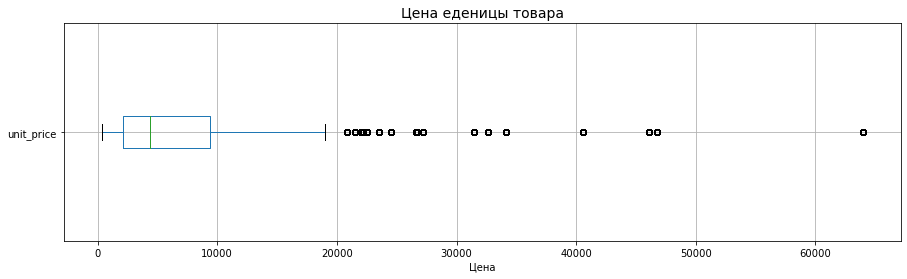

In [18]:
look_orders_unit_price = df_orders.boxplot(
    column = 'unit_price',
    vert = False,
    showfliers = True
)

fig = plt.gcf()
fig.set_size_inches(15, 4)

look_orders_unit_price.set_title('Цена еденицы товара', fontsize = 14)
look_orders_unit_price.set_xlabel('Цена')

plt.show()

In [19]:
# def iqr_mask(group):
#     q1 = group.quantile(0.25)
#     q3 = group.quantile(0.75)
#     iqr = q3 - q1
#     lower_bound = q1 - 3 * iqr
#     upper_bound = q3 + 3 * iqr
#     in_range_mask = (group >= lower_bound) & (group <= upper_bound)
#     nan_mask = group.isna()
#     return in_range_mask | nan_mask
# 
# df_mask = iqr_mask(df_orders['unit_price'])
# df_orders = df_orders[df_mask]
# df_orders = df_orders.reset_index(drop = True)

In [20]:
big_unit_price = df_orders[df_orders['unit_price'] > 60000]
big_unit_price

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
118,119,100,2024-01-17 08:10:57,Диван угловой,3,63932.38,191797.14,Мебель для дома,2024-01-15,2024-01-01
127,128,100,2024-02-24 01:25:44,Диван угловой,1,63932.38,63932.38,Мебель для дома,2024-02-19,2024-02-01
605,606,451,2024-01-25 10:10:17,Диван угловой,3,63932.38,191797.14,Мебель для дома,2024-01-22,2024-01-01
688,689,533,2024-01-31 16:46:18,Диван угловой,2,63932.38,127864.76,Мебель для дома,2024-01-29,2024-01-01
907,908,855,2024-02-24 07:46:37,Диван угловой,1,63932.38,63932.38,Мебель для дома,2024-02-19,2024-02-01
...,...,...,...,...,...,...,...,...,...,...
29963,30106,37227,2024-12-16 16:31:45,Диван угловой,2,63932.38,127864.76,Мебель для дома,2024-12-16,2024-12-01
30423,30601,38899,2024-11-28 01:10:04,Диван угловой,2,63932.38,127864.76,Мебель для дома,2024-11-25,2024-11-01
30480,30663,39141,2024-12-31 10:20:52,Диван угловой,3,63932.38,191797.14,Мебель для дома,2024-12-30,2024-12-01
30604,30795,39738,2024-12-24 06:03:52,Диван угловой,3,63932.38,191797.14,Мебель для дома,2024-12-23,2024-12-01


In [21]:
df_orders['total_price'].describe()

count     31357.000000
mean      14030.175560
std       18667.398146
min         339.000000
25%        3776.740000
50%        7554.640000
75%       17657.460000
max      191797.140000
Name: total_price, dtype: float64

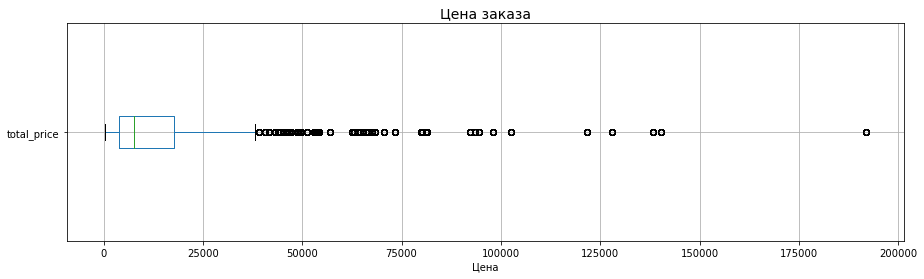

In [22]:
look_orders_total_price = df_orders.boxplot(
    column = 'total_price',
    vert = False,
    showfliers = True
)

fig = plt.gcf()
fig.set_size_inches(15, 4)

look_orders_total_price.set_title('Цена заказа', fontsize = 14)
look_orders_total_price.set_xlabel('Цена')

plt.show()

In [23]:
big_total_price = df_orders[df_orders['total_price'] > 100000]
big_total_price

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
118,119,100,2024-01-17 08:10:57,Диван угловой,3,63932.38,191797.14,Мебель для дома,2024-01-15,2024-01-01
136,137,100,2024-03-15 06:55:04,Кровать двуспальная,3,46763.44,140290.31,Мебель для дома,2024-03-11,2024-03-01
449,450,354,2024-05-08 20:23:32,Стол обеденный,3,40587.85,121763.55,Мебель для дома,2024-05-06,2024-05-01
605,606,451,2024-01-25 10:10:17,Диван угловой,3,63932.38,191797.14,Мебель для дома,2024-01-22,2024-01-01
616,617,451,2024-05-22 16:21:25,Тумба ТВ,3,46071.21,138213.62,Мебель для дома,2024-05-20,2024-05-01
...,...,...,...,...,...,...,...,...,...,...
30700,30924,40216,2024-12-01 14:56:01,Кровать двуспальная,3,46763.44,140290.31,Мебель для дома,2024-11-25,2024-12-01
30706,30930,40244,2024-11-30 14:47:00,Шкаф-купе,3,34164.33,102492.99,Мебель для дома,2024-11-25,2024-11-01
30855,31087,40984,2024-12-08 05:54:43,Стол обеденный,3,40587.85,121763.55,Мебель для дома,2024-12-02,2024-12-01
30955,31196,41314,2024-12-22 10:54:36,Стол обеденный,3,40587.85,121763.55,Мебель для дома,2024-12-16,2024-12-01


In [24]:
df_orders['order_week'].value_counts()

2024-04-29    839
2024-05-27    830
2024-07-08    814
2024-08-26    810
2024-08-12    805
2024-05-06    802
2024-05-20    794
2024-07-29    793
2024-04-15    781
2024-07-01    775
2024-07-15    759
2024-06-24    749
2024-07-22    747
2024-04-08    737
2024-04-22    731
2024-05-13    724
2024-08-19    707
2024-03-25    697
2024-06-10    695
2024-09-02    694
2024-09-09    686
2024-08-05    679
2024-06-03    677
2024-06-17    677
2024-09-16    671
2024-04-01    664
2024-03-11    627
2024-09-30    618
2024-03-18    614
2024-03-04    604
2024-10-07    590
2024-10-14    563
2024-09-23    554
2024-02-26    514
2024-10-21    509
2024-02-19    502
2024-11-11    501
2024-02-05    485
2024-12-09    481
2024-10-28    478
2024-11-04    476
2024-12-16    458
2024-11-18    443
2024-12-02    436
2024-02-12    423
2024-12-23    416
2024-01-29    399
2024-11-25    396
2024-01-22    308
2024-01-15    275
2024-01-08    157
2024-12-30    126
2024-01-01     67
Name: order_week, dtype: int64

In [25]:
df_orders['order_month'].value_counts()

2024-05-01    3518
2024-07-01    3413
2024-08-01    3393
2024-04-01    3124
2024-06-01    3058
2024-03-01    2791
2024-09-01    2756
2024-10-01    2478
2024-11-01    1990
2024-12-01    1955
2024-02-01    1917
2024-01-01     964
Name: order_month, dtype: int64

Таблица `df_costs`, содержит данные о маркетинговых затратах и каналах привлечения.

In [26]:
df_costs = df_costs.drop(columns = ['Unnamed: 0'])

In [27]:
df_costs.head()

,acq_channel,spend_month,budget
0,Affiliate,2024-01-01,179343.3875
1,Affiliate,2024-02-01,175488.4875
2,Affiliate,2024-03-01,164543.4750
3,Affiliate,2024-04-01,186869.9750
4,Affiliate,2024-05-01,166443.7750


In [28]:
df_costs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   acq_channel  88 non-null     object 
 1   spend_month  88 non-null     object 
 2   budget       88 non-null     float64
dtypes: float64(1), object(2)
memory usage: 2.2+ KB


In [29]:
df_costs.duplicated().sum()

0

In [30]:
df_costs['acq_channel'].value_counts()

Affiliate          13
Direct             13
Email Marketing    13
Social Media       13
SEO                13
TikTok             13
Google Ads         10
Name: acq_channel, dtype: int64

In [31]:
df_costs['spend_month'].value_counts()

2024-01-01    7
2024-02-01    7
2024-03-01    7
2024-04-01    7
2024-05-01    7
2024-06-01    7
2024-07-01    7
2024-08-01    7
2024-09-01    7
2024-10-01    7
2024-11-01    6
2024-12-01    6
2025-01-01    6
Name: spend_month, dtype: int64

In [32]:
df_costs['budget'].describe()

count    8.800000e+01
mean     2.196269e+05
std      3.373531e+05
min      6.674101e+03
25%      4.204593e+04
50%      1.114376e+05
75%      1.726050e+05
max      1.533683e+06
Name: budget, dtype: float64

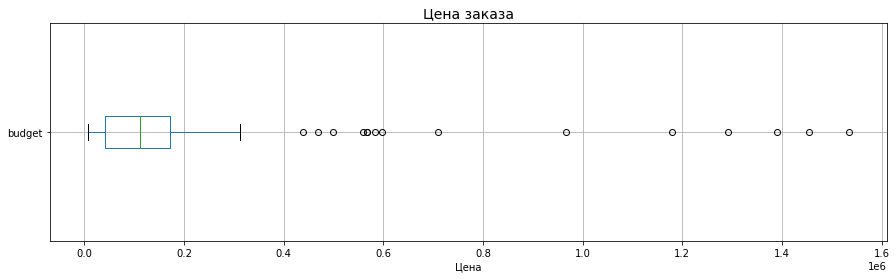

In [33]:
look_costs_budget = df_costs.boxplot(
    column = 'budget',
    vert = False,
    showfliers = True
)

fig = plt.gcf()
fig.set_size_inches(15, 4)

look_costs_budget.set_title('Цена заказа', fontsize = 14)
look_costs_budget.set_xlabel('Цена')

plt.show()

Таблица `df_users`, содержит данные о пользователях.

In [34]:
df_users.head()

,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01


In [35]:
df_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 3.0+ MB


In [36]:
df_users.duplicated().sum()

0

In [37]:
df_users['registration_date'].min()

Timestamp('2024-01-01 00:07:00')

In [38]:
df_users['registration_date'].max()

Timestamp('2024-12-31 23:44:00')

In [39]:
unique_user_id_users = df_users['user_id'].nunique()
unique_user_id_users

44151

In [40]:
df_users['age'].value_counts().sort_index(ascending = True)

18    835
19    852
20    809
21    809
22    843
23    800
24    876
25    865
26    808
27    825
28    801
29    892
30    830
31    862
32    830
33    777
34    849
35    787
36    841
37    792
38    861
39    808
40    889
41    831
42    854
43    849
44    860
45    856
46    877
47    819
48    839
49    834
50    813
51    794
52    818
53    834
54    822
55    855
56    829
57    814
58    801
59    865
60    828
61    771
62    857
63    805
64    891
65    826
66    836
67    785
68    848
69    840
70    859
Name: age, dtype: int64

In [41]:
df_users['gender'].value_counts()

F    22126
M    22025
Name: gender, dtype: int64

In [42]:
df_users['region'].value_counts()

Другие регионы        14516
Москва                10959
Санкт-Петербург        6690
Московская область     3549
Екатеринбург           2145
Нижний Новгород        1748
Новосибирск            1723
Ростов-на-Дону         1423
Краснодар              1398
Name: region, dtype: int64

In [43]:
df_users['acq_channel'].value_counts()

TikTok             19228
Google Ads          9319
Affiliate           6069
Social Media        4179
SEO                 3312
Email Marketing     2044
Name: acq_channel, dtype: int64

In [44]:
df_users['buyer_segment'].value_counts()

medium      16421
rare        13256
regular      7773
one_time     6701
Name: buyer_segment, dtype: int64

Таблица `df_events`, содержит данные о событиях.

In [45]:
df_events.head()

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


In [46]:
df_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      785859 non-null  int64         
 1   user_id       785859 non-null  int64         
 2   event_date    785859 non-null  datetime64[ns]
 3   event_type    785859 non-null  object        
 4   os            785859 non-null  object        
 5   device        785859 non-null  object        
 6   product_name  385740 non-null  object        
 7   event_week    785859 non-null  datetime64[ns]
 8   event_month   785859 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 54.0+ MB


In [47]:
df_events.duplicated().sum()

0

In [48]:
df_events_dubl = df_events[df_events.duplicated(subset = ['event_id', 'user_id', 'event_date'], keep = False)]
df_events_dubl

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month


In [49]:
df_events['event_date'].min()

Timestamp('2024-01-01 00:00:00')

In [50]:
df_events['event_date'].max()

Timestamp('2024-12-31 00:00:00')

In [51]:
unique_user_id_events = df_events['user_id'].nunique()
unique_user_id_events

22138

In [52]:
unique_event_id_events = df_events['event_id'].nunique()
unique_event_id_events

785859

In [53]:
steps_df_events = df_events[df_events['user_id'] == 100]
steps_df_events.head(20)

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01
25,3176,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
26,3177,100,2024-01-01,product_view,iOS,mobile,Тушь для ресниц,2024-01-01,2024-01-01
27,3178,100,2024-01-01,product_click,iOS,mobile,Горелка газовая,2024-01-01,2024-01-01
28,3179,100,2024-01-01,add_to_cart,iOS,mobile,Сумка кожаная,2024-01-01,2024-01-01
29,3180,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


In [54]:
df_events['event_type'].value_counts()

page_view            125663
product_view         125318
product_click        121946
add_to_cart          110675
checkout_start        92401
checkout_complete     84012
filter_apply          14243
user_login            14109
category_view         14040
remove_from_cart      14034
user_logout           13981
promo_view            13935
search                13909
banner_click          13826
wishlist_add          13767
Name: event_type, dtype: int64

In [55]:
df_events['os'] = df_events['os'].str.lower()

In [56]:
df_events['os'].value_counts()

windows    200499
android    197945
ios        195551
macos      191864
Name: os, dtype: int64

In [57]:
df_events['device'].value_counts()

mobile     263495
tablet     261288
desktop    261076
Name: device, dtype: int64

In [58]:
df_events['product_name'].value_counts()

Коврик для йоги         2030
Угги зимние             2018
Кроссовки для бега      2017
Пальто зимнее           2014
Макароны                2013
                        ... 
Лопата штыковая         1837
Микроволновка           1832
Ботинки классические    1832
Секатор садовый         1813
Брюки чино              1776
Name: product_name, Length: 200, dtype: int64

Данные качественные, дубликатов нет, пропуски не критичные (поле `product_name` в таблице событий). Типы данных соответствуют содержанию.

## Обзор ключевых метрик

Выполним верхнеуровневую оценку состояния продукта с помощью собранных витрин. Бизнес просит оценить текущее состояние — без глубокой сегментации и оценки сложных метрик. Выручка бизнеса — 5% комиссии от стоимости любой продажи. 

Посмотрим на общую динамику ключевых метрик.

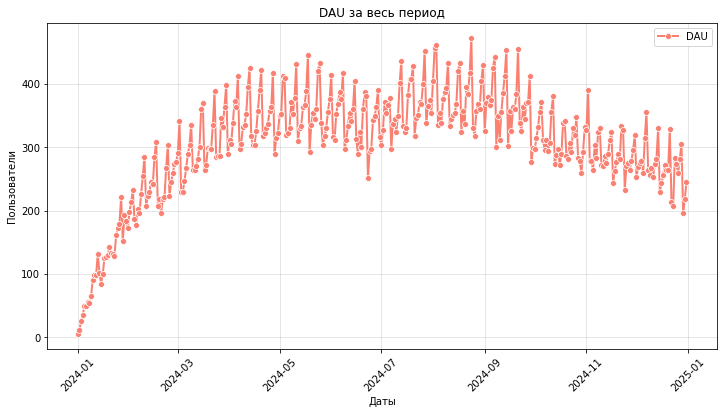

In [59]:
dau = (
    df_events
    .sort_values('event_date')
    .groupby('event_date')['user_id']
    .nunique()
    .reset_index(name = 'dau')
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = dau, 
    x = 'event_date', 
    y = 'dau',
    label = 'DAU', 
    color = 'salmon', 
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Пользователи')
plt.title('DAU за весь период')

plt.show()

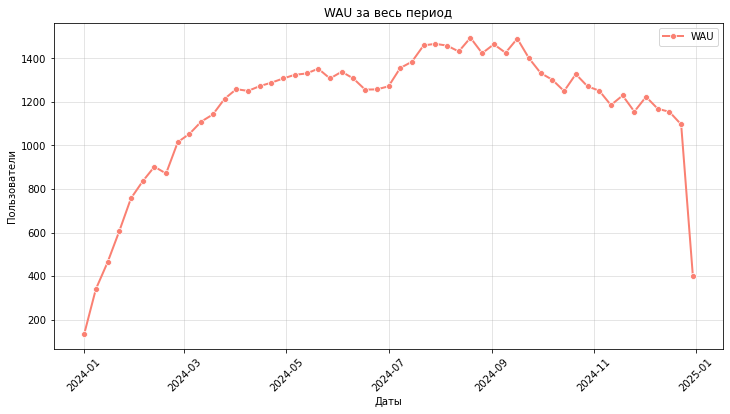

In [60]:
wau = (
    df_events
    .sort_values('event_week')
    .groupby('event_week')['user_id']
    .nunique()
    .reset_index(name = 'wau')
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = wau, 
    x = 'event_week', 
    y = 'wau',
    label = 'WAU', 
    color = 'salmon', 
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Пользователи')
plt.title('WAU за весь период')

plt.show()

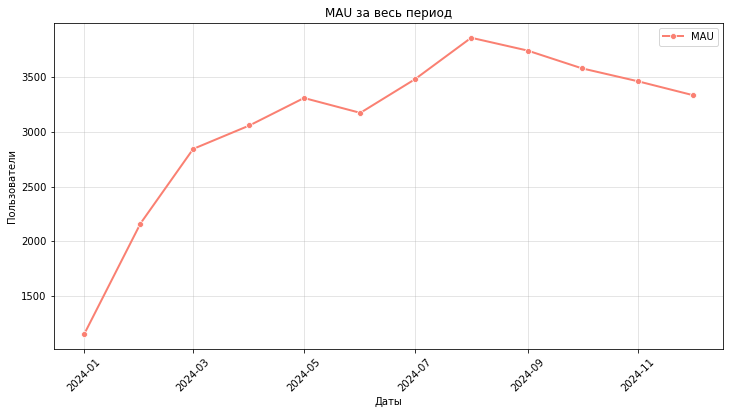

In [61]:
mau = (
    df_events
    .sort_values('event_month')
    .groupby('event_month')['user_id']
    .nunique()
    .reset_index(name = 'mau')
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = mau, 
    x = 'event_month', 
    y = 'mau',
    label = 'MAU', 
    color = 'salmon', 
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Пользователи')
plt.title('MAU за весь период')

plt.show()

Метрики показывают устойчивый рост и стабилизацию до начала лета, с июня идёт новый подъём, а затем тенденция на постоянное снижение активности пользователей.

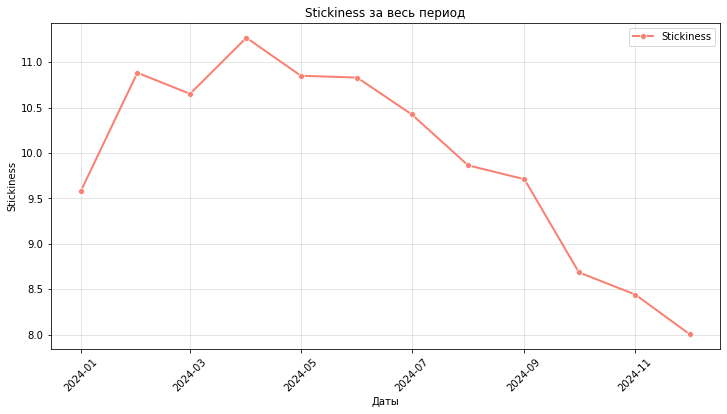

In [62]:
dau['month_str'] = dau['event_date'].dt.strftime('%Y-%m')

dau_month = (
    dau
    .groupby('month_str')['dau']
    .mean()
    .reset_index(name = 'dau_month')
)

mau['month_str'] = mau['event_month'].dt.strftime('%Y-%m')

stickiness = dau_month.merge(mau, on='month_str')
stickiness['stickiness'] = (stickiness['dau_month'] / stickiness['mau']) * 100
stickiness['date'] = pd.to_datetime(stickiness['month_str'])

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = stickiness, 
    x = 'date', 
    y = 'stickiness',
    label = 'Stickiness', 
    color = 'salmon', 
    marker = 'o',
    linewidth = 2
)
plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Stickiness')
plt.title('Stickiness за весь период')

plt.show()

После роста и небольшой стабилизации `stickiness` показывает постоянный тренд на снижение с июня, особенно резкий спад произощёл в сентябре. Доля возвращающихся пользователей относительно месячной аудитории сокращается.

Построим графики для retention. Товары, которые предлагает маркетплейс, мультикатегорийные, так что посмотрим возвращаемость в течение 4 недель по когортам.

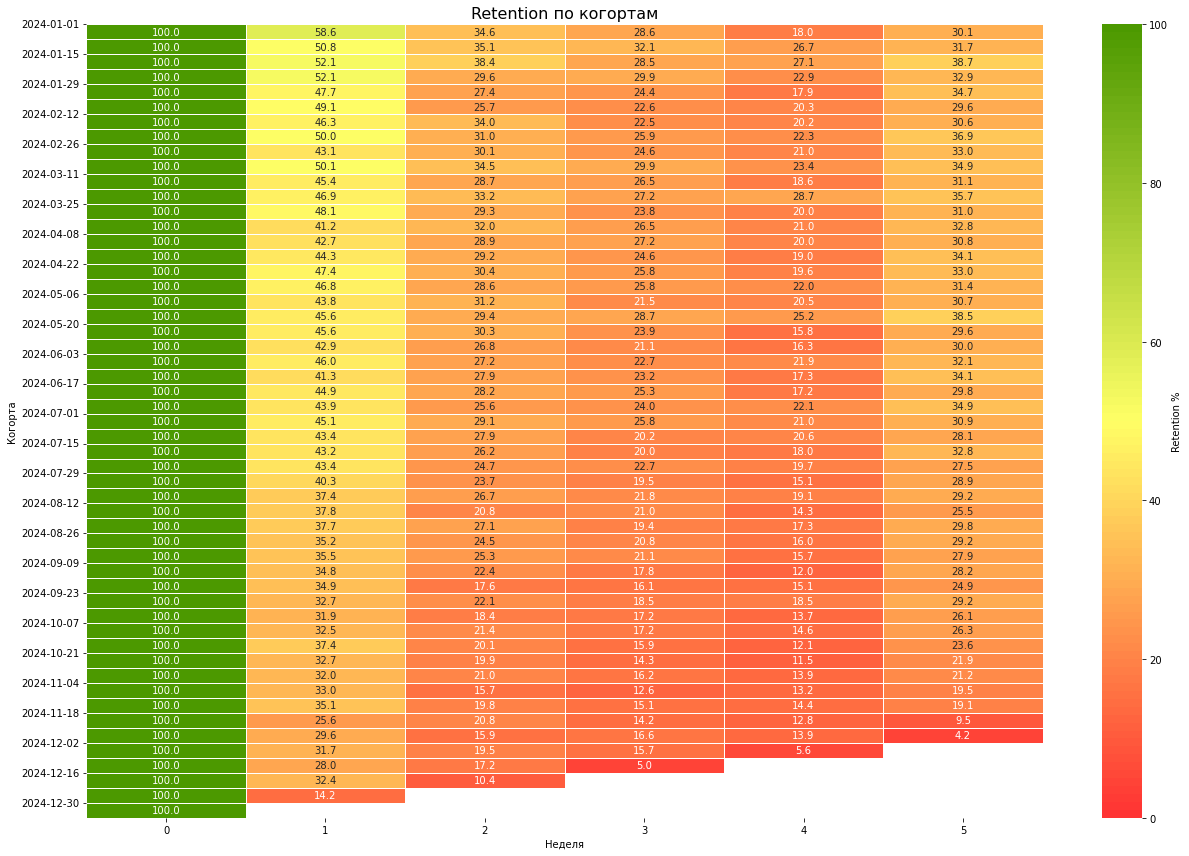

In [63]:
first_cohort_week = df_events.groupby('user_id')['event_week'].min().reset_index(name = 'cohort_week')

df_ret = df_events.merge(first_cohort_week, on = 'user_id')
df_ret['days_diff'] = (df_ret['event_week'] - df_ret['cohort_week']).dt.days
df_ret['obs_week'] = (df_ret['days_diff'] // 7).clip(upper = 5)

retention_raw = (
    df_ret
    .groupby(['cohort_week', 'obs_week'])['user_id']
    .nunique()
    .reset_index(name = 'users_count')
)

cohort_size = (
    df_ret
    .groupby('cohort_week')['user_id']
    .nunique()
    .reset_index(name = 'total_users')
)

retention_df = retention_raw.merge(cohort_size, on = 'cohort_week', how = 'left')
retention_df['retention_pct'] = (retention_df['users_count'] / retention_df['total_users']) * 100

pivot_ret = retention_df.pivot_table(
    index = 'cohort_week',
    columns = 'obs_week',
    values = 'retention_pct',
    aggfunc = 'first'
)

pivot_ret = pivot_ret.sort_index()
pivot_ret.columns = pivot_ret.columns.astype(int)

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N = 100)

plt.figure(figsize=(18, 12))

ax = sns.heatmap(
    pivot_ret,
    cmap = cmap,
    annot = True,
    fmt = ".1f",
    linewidths = .5,
    cbar_kws = {'label': 'Retention %'},
    vmin = 0, 
    vmax = 100
)

plt.title('Retention по когортам', fontsize = 16)
plt.xlabel('Неделя')
plt.ylabel('Когорта')

clean_labels = pivot_ret.index.strftime('%Y-%m-%d').tolist()
n_cohorts = len(clean_labels)

if n_cohorts > 20:
    step = 2
    tick_locs = range(0, n_cohorts, step)
    display_labels = clean_labels[::step]
else:
    tick_locs = range(n_cohorts)
    display_labels = clean_labels

ax.set_yticks(tick_locs)
ax.set_yticklabels(display_labels, rotation = 0, fontsize = 10)

plt.tight_layout()
plt.show()

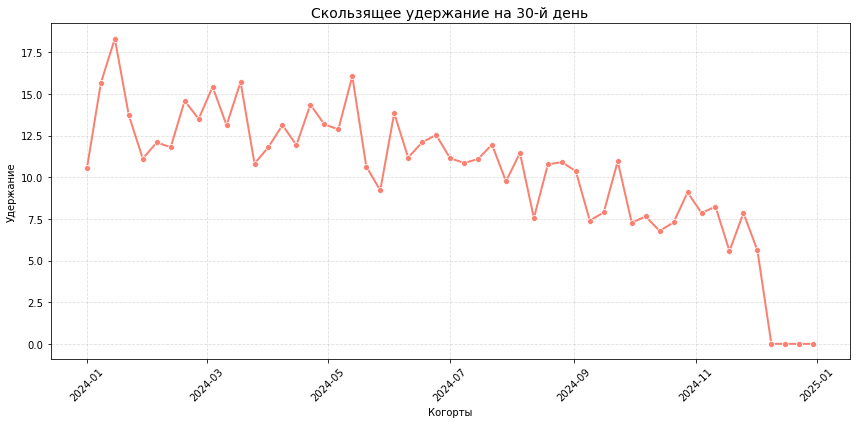

In [64]:
first_cohort_week = (
    df_events
    .groupby('user_id')['event_week']
    .min()
    .reset_index(name = 'cohort_week')
)

df_ret = df_events.merge(first_cohort_week, on = 'user_id')
df_ret['days_diff'] = (df_ret['event_date'] - df_ret['cohort_week']).dt.days
df_ret = df_ret[df_ret['days_diff'] <= 35]

cohort_size = (
    df_ret
    .groupby('cohort_week')['user_id']
    .nunique()
    .reset_index(name = 'total_users')
)

retained_users = (
    df_ret
    .query('days_diff >= 28 and days_diff <= 30')
    .groupby('cohort_week')['user_id']
    .nunique()
    .reset_index(name = 'retained_users')
)

retention_30d = cohort_size.merge(retained_users, on = 'cohort_week', how  = 'left')
retention_30d['retained_users'] = retention_30d['retained_users'].fillna(0)
retention_30d['retention_30d_pct'] = (retention_30d['retained_users'] / retention_30d['total_users']) * 100
retention_30d = retention_30d.sort_values('cohort_week')

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = retention_30d,
    x = 'cohort_week',
    y = 'retention_30d_pct',
    marker = 'o',
    linewidth = 2,
    color = 'salmon'
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45, fontsize = 10)

plt.xlabel('Когорты')
plt.ylabel('Удержание')
plt.title('Скользящее удержание на 30-й день', fontsize = 14)
plt.tight_layout()
plt.show()

До лета удержание было устойчивое. Ранние когорты демонстрируют более высокий Retention, с лета - стабильно ниже. Для e‑commerce такого типа 30‑дневный Retention приблизительно должен быть 5-12%, на графике очень сильное падение. Летом были изменения, после которых ухудшились retention и stickiness.

Посмотрим, как расходуется бюджет на привлечение.

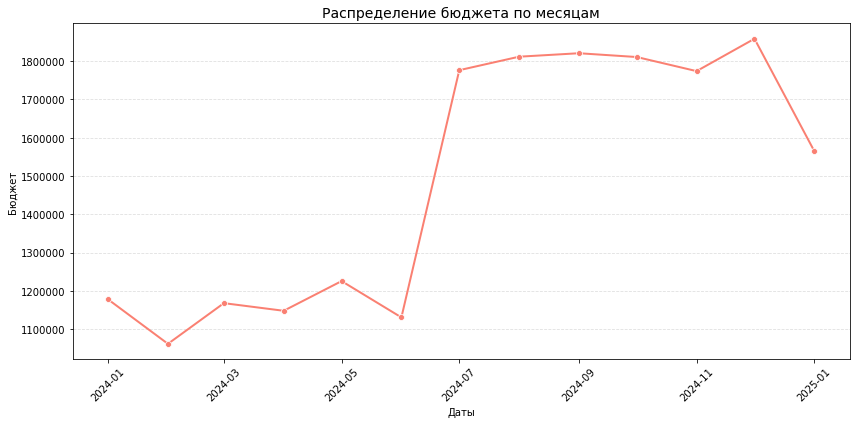

In [65]:
monthly_spend = df_costs.groupby('spend_month')['budget'].sum().reset_index(name = 'total_budget')
monthly_spend['spend_month'] = pd.to_datetime(monthly_spend['spend_month'])

plt.figure(figsize = (12, 6))

ax = sns.lineplot(
    data = monthly_spend,
    x = 'spend_month',
    y = 'total_budget',
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
formatter = ScalarFormatter()
formatter.set_scientific(False)
formatter.set_useOffset(False)
ax.yaxis.set_major_formatter(formatter)

plt.grid(axis = 'y', alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45, fontsize = 10)

ax.set_title('Распределение бюджета по месяцам', fontsize = 14)
ax.set_xlabel('Даты')
ax.set_ylabel('Бюджет')

plt.tight_layout()
plt.show()

Бюджет на рекламу резко вырос с началом лета - с 1200000 до 1800000. Как распределяется бюджет по каналам привлечения.

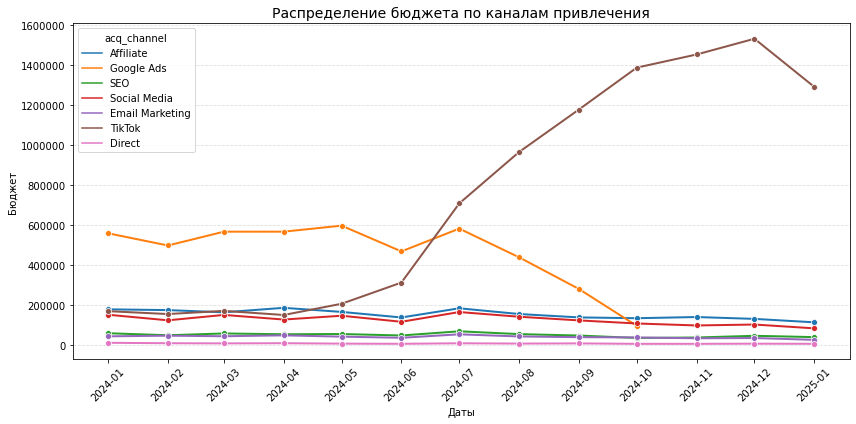

In [66]:
df_costs_channel = df_costs.copy()
df_costs_channel['spend_month'] = pd.to_datetime(df_costs_channel['spend_month'], errors = 'coerce')
df_costs_channel = df_costs_channel.dropna(subset = ['spend_month'])
df_costs_channel = df_costs_channel.sort_values('spend_month')

plt.figure(figsize = (12, 6))

ax = sns.lineplot(
    data = df_costs_channel,
    x = 'spend_month',
    y = 'budget',
    hue = 'acq_channel',
    marker = 'o',
    linewidth = 2
)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator())

formatter = ScalarFormatter()
formatter.set_scientific(False)
formatter.set_useOffset(False)
ax.yaxis.set_major_formatter(formatter)

plt.grid(axis = 'y', alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45, fontsize = 10)

plt.title('Распределение бюджета по каналам привлечения', fontsize = 14)
plt.xlabel('Даты')
plt.ylabel('Бюджет')

plt.tight_layout()
plt.show()

Похоже как раз с начала лета произошли изменения в  распределении маркетинго бюджета. На канал `TikTok` траты выросли в разы с июня и постоянно увеличивались, в то же время `Google Ads` резко опустился в приоритете и слился со всеми другими источниками привлечения, которые тоже немного просели с июля. Надо будет узнать, окупились ли такие траты, потому что посещаемость маркетплейса начала стабильно снижаться с очени.

Посчитаем суммарную выручку GMV на каждый месяц (платформа получает 5%).

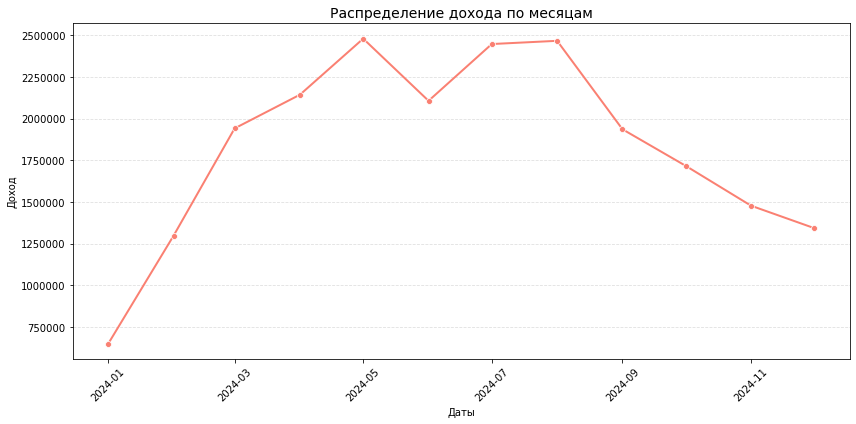

In [67]:
monthly_sales = df_orders.groupby('order_month')['total_price'].sum().reset_index()
monthly_sales['marketplace_revenue'] = monthly_sales['total_price'] * 0.05
monthly_sales['marketplace_revenue'] = monthly_sales['marketplace_revenue'].round(2)
monthly_sales = monthly_sales.rename(columns = {'total_price': 'total_sales_gmv'})

plt.figure(figsize = (12, 6))

ax = sns.lineplot(
    data = monthly_sales,
    x = 'order_month',
    y = 'marketplace_revenue',
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
formatter = ScalarFormatter()
formatter.set_scientific(False)
formatter.set_useOffset(False)
ax.yaxis.set_major_formatter(formatter)

plt.grid(axis = 'y', alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45, fontsize = 10)

ax.set_title('Распределение дохода по месяцам', fontsize = 14)
ax.set_xlabel('Даты')
ax.set_ylabel('Доход')

plt.tight_layout()
plt.show()

Месячный доход от маркетплейса показывал стабильный рост до начала лета, затем наступила стагнация и быстрый спад с сентября. Показатель конца года уже ближе к цифрам из начала графика. Направление огромного бюджета на рекламу в тиктоке не помогло увеличить прибыль.

Теперь посмотрим воронку пользователей по уникальным `user_id`.

In [68]:
steps = ['page_view', 'product_view', 'product_click', 'add_to_cart', 'checkout_start', 'checkout_complete']

df_events_steps = df_events[df_events['event_type'].isin(steps)]
df_events_steps_counts = df_events_steps.groupby('event_type')['user_id'].nunique().reindex(steps)

funnel_df_events = pd.DataFrame({
   'step': df_events_steps_counts.index,
   'users': df_events_steps_counts.values
})

df_events_first_step_users = funnel_df_events.loc[0, 'users']
funnel_df_events['conversion_from_first_%'] = (funnel_df_events['users'] / df_events_first_step_users * 100).round(1)
funnel_df_events['conversion_from_previous_%'] = (funnel_df_events['users'] / funnel_df_events['users'].shift(1) * 100).round(1)

funnel_df_events

,step,users,conversion_from_first_%,conversion_from_previous_%
0,page_view,22098,100.0,NaN
1,product_view,22069,99.9,99.9
2,product_click,21745,98.4,98.5
3,add_to_cart,20411,92.4,93.9
4,checkout_start,16769,75.9,82.2
5,checkout_complete,13897,62.9,82.9


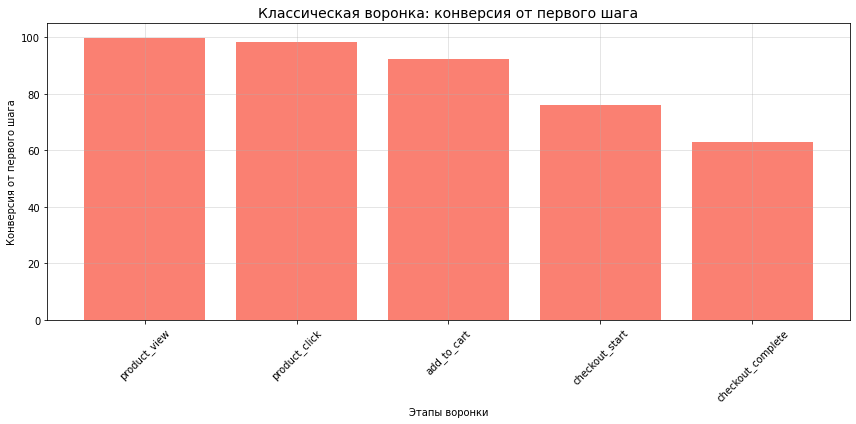

In [69]:
plt.figure(figsize = (12, 6))

plot_df_events = funnel_df_events.iloc[1:]

plt.bar(
    plot_df_events['step'], 
    plot_df_events['conversion_from_first_%'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Классическая воронка: конверсия от первого шага', fontsize = 14)
plt.ylabel('Конверсия от первого шага')
plt.xlabel('Этапы воронки')

plt.tight_layout()
plt.show()

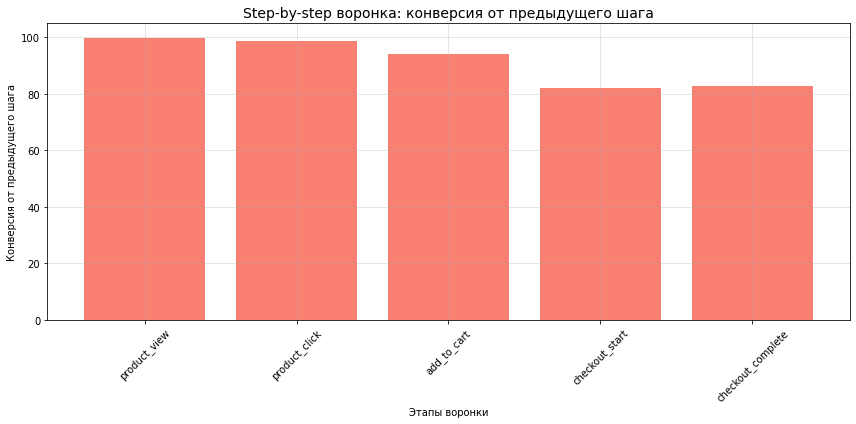

In [70]:
plt.figure(figsize = (12, 6))

plot_df_events_p = funnel_df_events.iloc[1:]

plt.bar(
    plot_df_events_p['step'], 
    plot_df_events_p['conversion_from_previous_%'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Step-by-step воронка: конверсия от предыдущего шага', fontsize = 14)
plt.ylabel('Конверсия от предыдущего шага')
plt.xlabel('Этапы воронки')

plt.tight_layout()
plt.show()

Воронка без критично узких, до последнего этапа доходит больше половины пользователей.


### Итоги обзора

До начала лета метрики продукта росли в стабильной тренде, активность и удержание росли. Прибыль шла вверх. В мае метрики распределялись так: MAU ~ 3250 человек, удержание ~15%, GMV 250000 и расходы на привлечение 1200000.

С началом лета изменился подход к распределению бюджета на привлечение: канал `TikTok` стал получать в разы больше денег, чем все остальные источники, в то же время `Google Ads` опустился ко всем оставшимся каналам ниже 200000. Месячные траты на бюджет увеличились с 1200000 до 1800000. Вместе с этим комиссия продукта стагнировала и начала резко падать с 2500000 в августе до 1300000 в декабре. Врятли на это повлияла сезонность, маркетплейс предоставляет общирные и разноплановые категории товара. К концу года также просели метрики посещений и удержания.

## Оценка метрик монетизации и юнит-экономики

Выполним анализ монетизации. Определим, сколько зарабатывает продукт и сколько тратится на привлечение пользователей. Изучим средний доход, который компания получает от одного пользователя, рассчитаем ARPU.

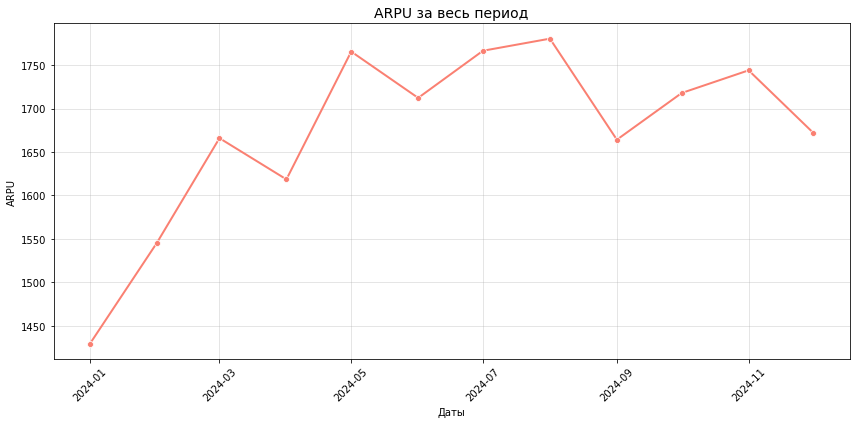

In [71]:
df_calc = df_orders.copy()
df_calc['revenue_business'] = df_calc['total_price'] * 0.05
df_calc['order_year_month'] = df_calc['order_date'].dt.to_period('M')

arpu_by_month = (
    df_calc
    .groupby('order_year_month')
    .agg(
        total_revenue = ('revenue_business', 'sum'),
        active_users = ('user_id', 'nunique')
    )
    .reset_index()
)

arpu_by_month['arpu'] = (
    arpu_by_month['total_revenue'] / arpu_by_month['active_users']
).fillna(0).round(2)

arpu_by_month['order_date_plot'] = arpu_by_month['order_year_month'].dt.to_timestamp()

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = arpu_by_month,
    x = 'order_date_plot',
    y = 'arpu',
    marker = 'o',
    linewidth = 2,
    color = 'salmon'
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('ARPU')
plt.title('ARPU за весь период', fontsize = 14)

plt.tight_layout()
plt.show()

ARPU платящего пользователя ~ 1435-1785. Рост был до конца лета, затем произошло снижение в сентябре, попытка выровниться и снова падение к концу года, периоду активных предновогодних продаж. Это согласуется с общим падением дохода, которое мы видели на графике до этого.

Средний чек AOV.

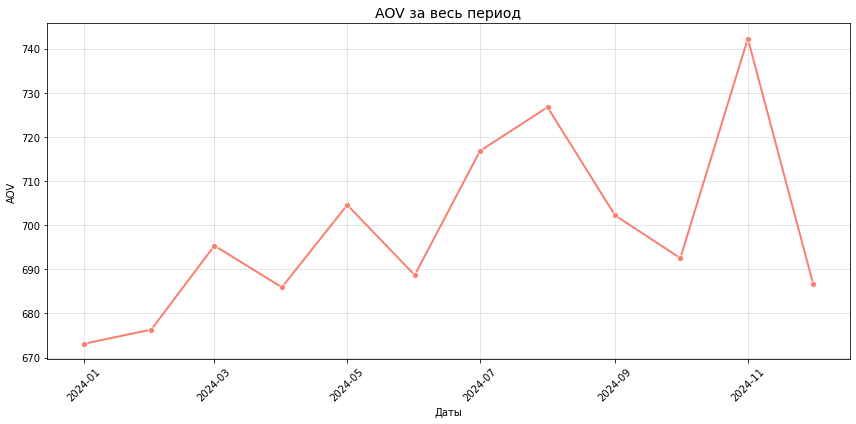

In [72]:
aov_by_month = (
    df_calc
    .groupby('order_year_month')
    .agg(
        total_revenue = ('revenue_business', 'sum'),
        total_orders = ('order_id', 'nunique')
    )
    .reset_index()
)

aov_by_month['aov'] = (aov_by_month['total_revenue'] / aov_by_month['total_orders']).round(2)
aov_by_month['order_year_month'] = aov_by_month['order_year_month'].apply(lambda x: x.to_timestamp())
aov_by_month = aov_by_month.sort_values('order_year_month')

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = aov_by_month,
    x = 'order_year_month',
    y = 'aov',
    marker = 'o',
    linewidth = 2,
    color = 'salmon'
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('AOV')
plt.title('AOV за весь период', fontsize = 14)

plt.tight_layout()
plt.show()

Был тренд на рост до августа, потом начались резкие передады, возможно из-за предновогодних активностей, распродаж.

### Показатели эффективности

Доработаем датафрейм с профилями пользователей чтобы  оченить эффективность маркетинговых трат.

In [73]:
df_costs['spend_month'] = pd.to_datetime(df_costs['spend_month'])
df_orders['order_date'] = pd.to_datetime(df_orders['order_date'])
df_users['registration_date'] = pd.to_datetime(df_users['registration_date'])

users_count = (
    df_users
    .groupby(['acq_channel', 'cohort_month'])
    .agg(users_in_cohort = ('user_id', 'nunique'))
    .reset_index()
)

costs_with_count = df_costs.merge(
    users_count,
    left_on = ['acq_channel', 'spend_month'],
    right_on = ['acq_channel', 'cohort_month'],
    how = 'left'
)

costs_with_count['cac'] = costs_with_count.apply(
    lambda x: x['budget'] / x['users_in_cohort'] if x['users_in_cohort'] > 0 else 0, 
    axis = 1
)

df_orders_users = df_orders.merge(
    df_users[['user_id', 'registration_date', 'cohort_month', 'acq_channel']],
    on = 'user_id',
    how = 'left'
)

df_orders_users['lifetime'] = (df_orders_users['order_date'] - df_orders_users['registration_date']).dt.days
df_30d = df_orders_users[(df_orders_users['lifetime'] >= 0) & (df_orders_users['lifetime'] < 30)].copy()

commission_rate = 0.05
df_30d['revenue'] = df_30d['total_price'] * commission_rate

user_revenue_30d = (
    df_30d
    .groupby(['user_id', 'acq_channel'])['revenue']
    .sum()
    .reset_index()
)

users_metrics = df_users[['user_id', 'cohort_month', 'acq_channel']].merge(
    user_revenue_30d,
    on = ['user_id', 'acq_channel'],
    how = 'left'
).merge(
    costs_with_count[['acq_channel', 'cohort_month', 'cac']],
    on = ['acq_channel', 'cohort_month'],
    how = 'left'
)

users_metrics['revenue'] = users_metrics['revenue'].fillna(0)

roi_cohort = (
    users_metrics
    .groupby('cohort_month')
    .agg(
        avg_ltv_30d = ('revenue', 'mean'),
        avg_cac = ('cac', 'mean'),
        users_count = ('user_id', 'nunique')
    )
    .reset_index()
)

roi_cohort['roi_percent'] = ((roi_cohort['avg_ltv_30d'] - roi_cohort['avg_cac']) / roi_cohort['avg_cac']) * 100

In [74]:
roi_cohort

,cohort_month,avg_ltv_30d,avg_cac,users_count,roi_percent
0,2024-01-01,353.557324,390.474426,2985,-9.454422
1,2024-02-01,392.473031,387.944504,2711,1.167313
2,2024-03-01,403.129785,390.806141,2965,3.153391
3,2024-04-01,441.126007,391.735726,2905,12.608061
4,2024-05-01,412.246661,397.134348,3066,3.805340
5,2024-06-01,347.525198,399.843749,2810,-13.084749
6,2024-07-01,300.177475,402.700178,4388,-25.458817
7,2024-08-01,226.682491,407.059325,4431,-44.312174
8,2024-09-01,187.866435,405.708053,4466,-53.694181
9,2024-10-01,155.434093,406.335241,4440,-61.747326


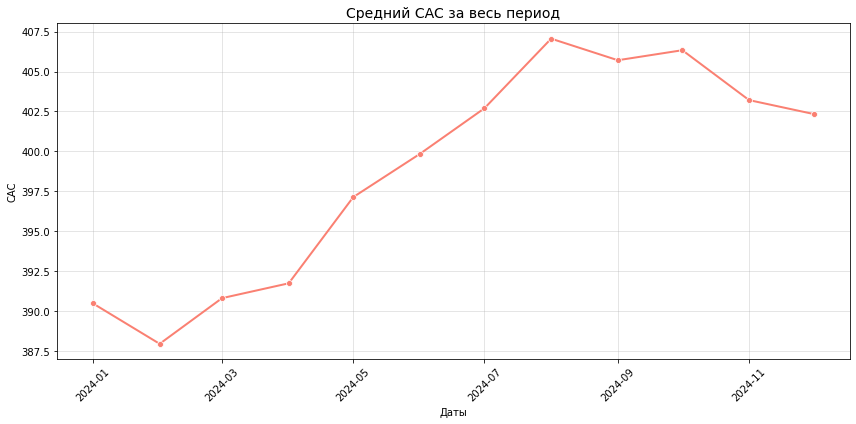

In [75]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi_cohort, 
    x = 'cohort_month', 
    y = 'avg_cac', 
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('CAC')
plt.title('Средний CAC за весь период', fontsize = 14)

plt.tight_layout()
plt.show()

Затраты на привлечение выросли, но количество пользователей тоже росло со временем, так что подъём получился с ~390 до 405 и относительно стабилен.

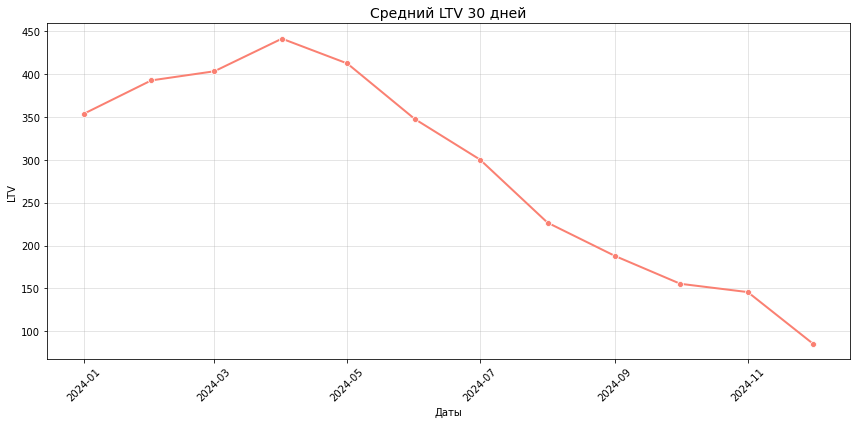

In [76]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi_cohort,
    x = 'cohort_month',
    y = 'avg_ltv_30d',
    marker = 'o',
    linewidth = 2,
    color = 'salmon'
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('LTV')
plt.title('Средний LTV 30 дней', fontsize = 14)

plt.tight_layout()
plt.show()

Выручка на пользователя снижается, это согласуется с падением удержания и возврощаемости. Комиссия упала с января по декабрь в 4 раза.

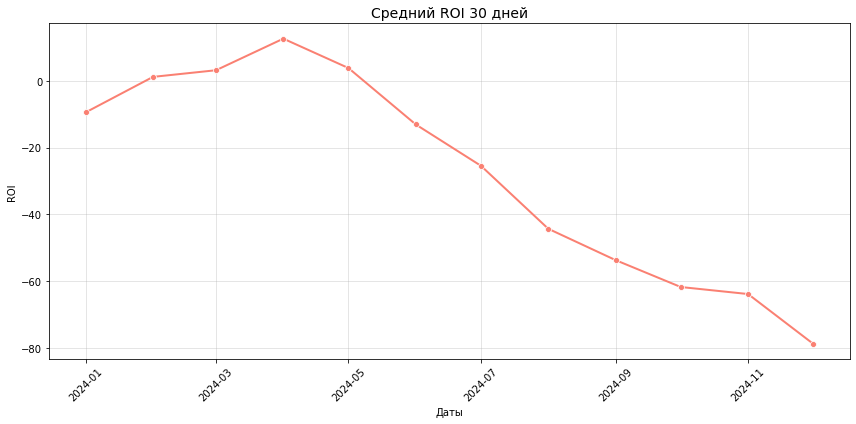

In [77]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi_cohort,
    x = 'cohort_month',
    y = 'roi_percent',
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('ROI')
plt.title('Средний ROI 30 дней', fontsize = 14)

plt.tight_layout()
plt.show()

С лета доходность стала отрицательной и постоянно подает.

Посмотрим оценочные сроки окупаемости Payback Period.

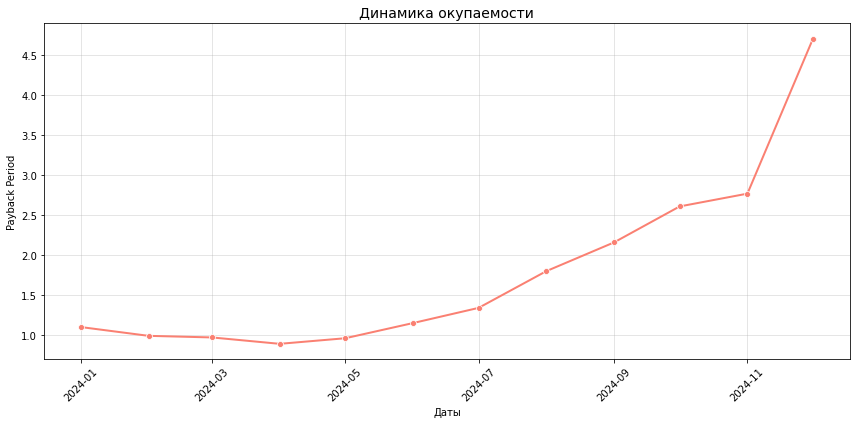

In [78]:
roi_cohort['payback_period_months'] = roi_cohort.apply(
    lambda x: x['avg_cac'] / x['avg_ltv_30d'] if x['avg_ltv_30d'] > 0 else float('inf'),
    axis = 1
)

roi_cohort['payback_period_months'] = roi_cohort['payback_period_months'].round(2)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi_cohort,
    x = 'cohort_month',
    y = 'payback_period_months',
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Payback Period')
plt.title('Динамика окупаемости', fontsize = 14)

plt.tight_layout()
plt.show()

Бюджет на привлечение значительно вырос, но относительно увеличения пользователей это нивелируется. Но качество этих пользователей значительно просело - они либо покупают реже, либо меньше тратят, либо вообще не покупают в первые 30 дней. Комиссия с каждым месяцем после весны падает: с ~450 в мае до 150 к ноябрю. Метрика ROI показывает постоянно снижающуюся убыточность с  июня. Срок окупаемости составлял примерно 1 месяц, к концу года уже 2.7 месяца. Решение нагнать трафик из `TikTok` вливанием огромного бюджета в ущерб другим источниками привлечения отразилось на монетизации маркетплейса очень негативным образом (не то что бы `TikTok` плохой канал, может неправильно настроили таргет и т.д.).

## Выводы по этапам 2 и 3

В пераой половине года метрики продукта показывали постепенный органический рост: увеличивались MAU, DAU, удержание в нормальных для маркетплейса такого типа 10-15%, увеличивались выручка, LTV достигал максимума весной. Бюджет на рекламу составлял ~ 1.2 млн ₽ в месяц.

В начале лета (с июня) произошли значительные изменения в маркетинговой системе, траты на рекламу выросли до ~2-2.5 млн ₽, основной упор сделали на канал привлечения `TikTok`, лидирующий до этого канал `Google Ads` практически перестал получать финансирование, все оставшимися трендом идут вниз. Возвращаемость когорт снизилась уже с первой недели: с 45-50% в начале года до 30-40% после июня. LTV поздних когорт хуже. Срок окупаемости растёт.

Модель привлечения стала убыточной. Важные метрики монетизации трендово идут вниз  к концу года, даже не устаканиваются. Рост количества пользователей и прибыль от них не перекрывает траты. Снижение выручки происходит на фоне падения удержания и конверсии, несмотря на рост привлечения. Это указывает на проблему качества трафика.

## Поиск инсайтов, точек роста и сегментация

Перейдём к сегментации и точечным наблюдениям. Посмотрим вглубь данных: по каналам, сегментам пользователей, категориям товаров, регионам, типам устройств.

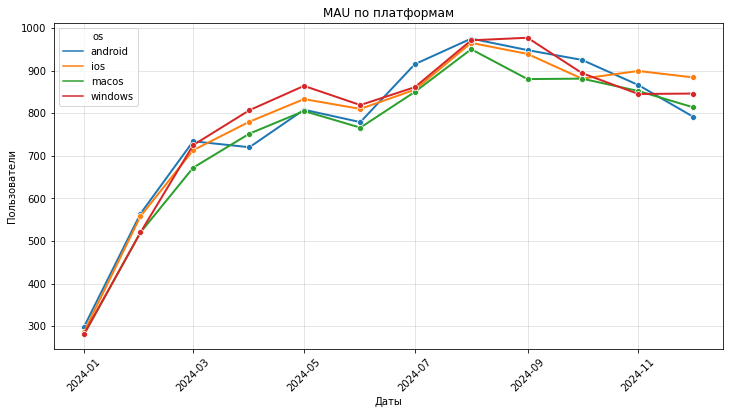

In [79]:
mau_os = (
    df_events
    .sort_values('event_month')
    .groupby(['event_month', 'os'])['user_id']
    .nunique()
    .reset_index(name = 'mau')
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = mau_os, 
    x = 'event_month', 
    y = 'mau',
    hue = 'os',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Пользователи')
plt.title('MAU по платформам')

plt.show()

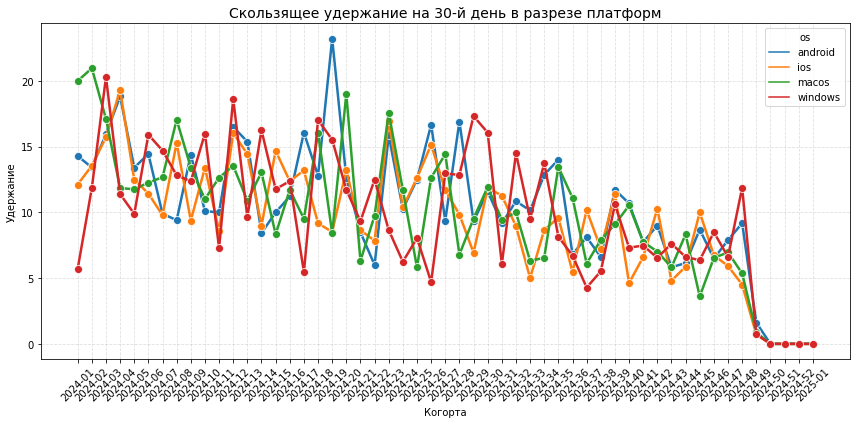

In [80]:
first_visit = (
    df_events
    .groupby('user_id')['event_date']
    .min()
    .reset_index(name = 'first_dt')
)

df_cohort = df_events.merge(first_visit, on = 'user_id', how = 'inner')
df_cohort['age_days'] = (df_cohort['event_date'] - df_cohort['first_dt']).dt.days
df_cohort = df_cohort[df_cohort['age_days'] <= 35]

df_cohort['cohort_week'] = (
    df_cohort['first_dt'].dt.isocalendar().year.astype(str) + '-' + 
    df_cohort['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

cohort_size = (
    df_cohort
    .groupby(['cohort_week', 'os'])['user_id']
    .nunique()
    .reset_index(name = 'total_users')
)

retained_users = (
    df_cohort
    .query('age_days >= 28 and age_days <= 30')
    .groupby(['cohort_week', 'os'])['user_id']
    .nunique()
    .reset_index(name = 'retained_users')
)

retention_30d = cohort_size.merge(retained_users, on = ['cohort_week', 'os'], how = 'left')
retention_30d['retained_users'] = retention_30d['retained_users'].fillna(0)
retention_30d['retention_30d_pct'] = (retention_30d['retained_users'] / retention_30d['total_users']) * 100

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=retention_30d,
    x = 'cohort_week',
    y = 'retention_30d_pct',
    hue = 'os',
    marker = 'o',
    linewidth = 2.5,
    markersize = 8
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45, fontsize = 10)

plt.xlabel('Когорта')
plt.ylabel('Удержание')
plt.title('Скользящее удержание на 30-й день в разрезе платформ', fontsize = 14)

plt.tight_layout()
plt.show()

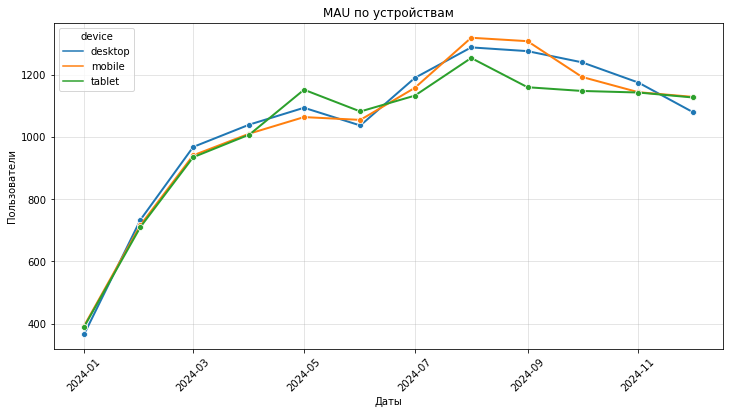

In [81]:
mau_device = (
    df_events
    .sort_values('event_month')
    .groupby(['event_month', 'device'])['user_id']
    .nunique()
    .reset_index(name = 'mau')
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = mau_device, 
    x = 'event_month', 
    y = 'mau',
    hue = 'device',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Пользователи')
plt.title('MAU по устройствам')

plt.show()

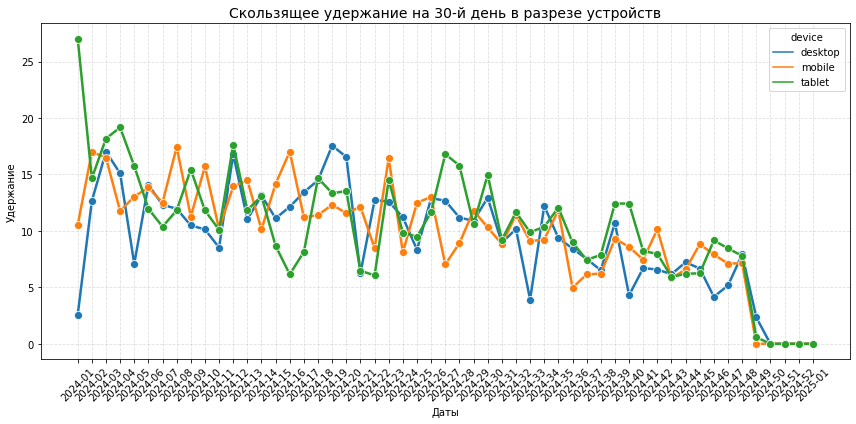

In [82]:
cohort_size = (
    df_cohort
    .groupby(['cohort_week', 'device'])['user_id']
    .nunique()
    .reset_index(name = 'total_users')
)

retained_users = (
    df_cohort
    .query('age_days >= 28 and age_days <= 30')
    .groupby(['cohort_week', 'device'])['user_id']
    .nunique()
    .reset_index(name = 'retained_users')
)

retention_30d = cohort_size.merge(retained_users, on = ['cohort_week', 'device'], how = 'left')
retention_30d['retained_users'] = retention_30d['retained_users'].fillna(0)
retention_30d['retention_30d_pct'] = (retention_30d['retained_users'] / retention_30d['total_users']) * 100

plt.figure(figsize=(12, 6))

sns.lineplot(
    data = retention_30d,
    x = 'cohort_week',
    y = 'retention_30d_pct',
    hue = 'device',
    marker = 'o',
    linewidth = 2.5,
    markersize = 8
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45, fontsize = 10)

plt.xlabel('Даты')
plt.ylabel('Удержание')
plt.title('Скользящее удержание на 30-й день в разрезе устройств', fontsize = 14)

plt.tight_layout()
plt.show()

Значимой разницы по устройствам и платформам нет. Изучим воронку маркетплейса детальнее.

In [83]:
mobile_df_events = df_events[df_events['device'] == 'mobile']
tablet_df_events = df_events[df_events['device'] == 'tablet']
desktop_df_events = df_events[df_events['device'] == 'desktop']

counts_mobile = mobile_df_events[mobile_df_events['event_type'].isin(steps)]
counts_mobile_agg = counts_mobile.groupby('event_type')['user_id'].nunique().reindex(steps)
mobile_funnel = (counts_mobile_agg / counts_mobile_agg.shift(1) * 100).round(1)

counts_tablet = tablet_df_events[tablet_df_events['event_type'].isin(steps)]
counts_tablet_agg = counts_tablet.groupby('event_type')['user_id'].nunique().reindex(steps)
tablet_funnel = (counts_tablet_agg / counts_tablet_agg.shift(1) * 100).round(1)

counts_desktop = desktop_df_events[desktop_df_events['event_type'].isin(steps)]
counts_desktop_agg = counts_desktop.groupby('event_type')['user_id'].nunique().reindex(steps)
desktop_funnel = (counts_desktop_agg / counts_desktop_agg.shift(1) * 100).round(1)

funnel_compare_df_events = pd.DataFrame({
    'step': steps[1:],
    'mobile': mobile_funnel.iloc[1:].values,
    'tablet': tablet_funnel.iloc[1:].values,
    'desktop': desktop_funnel.iloc[1:].values
})

funnel_compare_df_events

,step,mobile,tablet,desktop
0,product_view,99.9,99.9,99.8
1,product_click,98.6,98.5,98.5
2,add_to_cart,93.7,94.1,93.8
3,checkout_start,81.4,82.0,83.1
4,checkout_complete,82.7,82.3,83.7


In [84]:
windows_df_events = df_events[df_events['os'] == 'windows']
android_df_events = df_events[df_events['os'] == 'android']
ios_df_events = df_events[df_events['os'] == 'ios']
macos_df_events = df_events[df_events['os'] == 'macos']

counts_windows = windows_df_events[windows_df_events['event_type'].isin(steps)]
counts_windows_agg = counts_windows.groupby('event_type')['user_id'].nunique().reindex(steps)
windows_funnel = (counts_windows_agg / counts_windows_agg.shift(1) * 100).round(1)

counts_android = android_df_events[android_df_events['event_type'].isin(steps)]
counts_android_agg = counts_android.groupby('event_type')['user_id'].nunique().reindex(steps)
android_funnel = (counts_android_agg / counts_android_agg.shift(1) * 100).round(1)

counts_ios = ios_df_events[ios_df_events['event_type'].isin(steps)]
counts_ios_agg = counts_ios.groupby('event_type')['user_id'].nunique().reindex(steps)
ios_funnel = (counts_ios_agg / counts_ios_agg.shift(1) * 100).round(1)

counts_macos = macos_df_events[macos_df_events['event_type'].isin(steps)]
counts_macos_agg = counts_macos.groupby('event_type')['user_id'].nunique().reindex(steps)
macos_funnel = (counts_macos_agg / counts_macos_agg.shift(1) * 100).round(1)

funnel_compare_df_events_os = pd.DataFrame({
    'step': steps[1:],
    'windows': windows_funnel.iloc[1:].values,
    'android': android_funnel.iloc[1:].values,
    'ios': ios_funnel.iloc[1:].values,
    'macos': macos_funnel.iloc[1:].values
})

funnel_compare_df_events_os

,step,windows,android,ios,macos
0,product_view,99.9,99.8,99.9,99.9
1,product_click,98.7,98.5,98.4,98.6
2,add_to_cart,93.8,94.3,93.8,93.6
3,checkout_start,82.3,82.2,82.3,81.8
4,checkout_complete,82.2,83.7,82.4,83.2


Разницы в воронках по устройствам и платформам почти нет. Изучим метрики монетизации в разрезе каналов привлечения.

In [85]:
df_costs['spend_month'] = pd.to_datetime(df_costs['spend_month']).dt.to_period('M')
df_orders['order_date'] = pd.to_datetime(df_orders['order_date'])
df_users['registration_date'] = pd.to_datetime(df_users['registration_date'])
df_users['cohort_month'] = df_users['registration_date'].dt.to_period('M')

users_count = (
    df_users
    .groupby(['acq_channel', 'cohort_month'])
    .agg(users_in_cohort = ('user_id', 'nunique'))
    .reset_index()
)

df_costs['spend_month_period'] = df_costs['spend_month']

costs_with_count = df_costs.merge(
    users_count,
    left_on = ['acq_channel', 'spend_month_period'],
    right_on = ['acq_channel', 'cohort_month'],
    how = 'left'
)

costs_with_count['cac'] = costs_with_count.apply(
    lambda x: x['budget'] / x['users_in_cohort'] if x['users_in_cohort'] > 0 else np.nan, 
    axis = 1
)

cac_summary = (
    costs_with_count
    .groupby(['acq_channel', 'cohort_month'])['cac']
    .mean()
    .reset_index()
)

df_orders_users = df_orders.merge(
    df_users[['user_id', 'registration_date', 'cohort_month', 'acq_channel']],
    on = 'user_id',
    how = 'left'
)

df_orders_users['lifetime'] = (df_orders_users['order_date'] - df_orders_users['registration_date']).dt.days
df_30d = df_orders_users[(df_orders_users['lifetime'] >= 0) & (df_orders_users['lifetime'] < 30)].copy()

commission_rate = 0.05
df_30d['revenue'] = df_30d['total_price'] * commission_rate

user_revenue_30d = (
    df_30d
    .groupby(['user_id', 'acq_channel'])['revenue']
    .sum()
    .reset_index()
)

users_metrics = df_users[['user_id', 'cohort_month', 'acq_channel']].merge(
    user_revenue_30d,
    on = ['user_id', 'acq_channel'],
    how = 'left'
)

users_metrics = users_metrics.merge(
    cac_summary,
    on = ['acq_channel', 'cohort_month'],
    how = 'left'
)


users_metrics['revenue'] = users_metrics['revenue'].fillna(0)

roi_cohort_by_channel = (
    users_metrics
    .groupby(['cohort_month', 'acq_channel'])
    .agg(
        avg_ltv_30d = ('revenue', 'mean'),
        avg_cac = ('cac', 'mean'),
        users_count = ('user_id', 'nunique'),
        zero_buyers = ('revenue', lambda x: (x == 0).sum())
    )
    .reset_index()
)

roi_cohort_by_channel['payback_period'] = roi_cohort_by_channel.apply(
    lambda x: x['avg_cac'] / x['avg_ltv_30d'] if x['avg_ltv_30d'] > 0 else np.inf, 
    axis = 1
)

roi_cohort_by_channel['roi_percent'] = ((roi_cohort_by_channel['avg_ltv_30d'] - roi_cohort_by_channel['avg_cac']) / roi_cohort_by_channel['avg_cac']) * 100
roi_cohort_by_channel['zero_buyers_rate'] = (roi_cohort_by_channel['zero_buyers'] / roi_cohort_by_channel['users_count']) * 100
roi_cohort_by_channel = roi_cohort_by_channel.sort_values(['cohort_month', 'acq_channel'])
roi_cohort_by_channel['cohort_date'] = roi_cohort_by_channel['cohort_month'].dt.to_timestamp()

roi_cohort_by_channel.head()

,cohort_month,acq_channel,avg_ltv_30d,avg_cac,users_count,zero_buyers,payback_period,roi_percent,zero_buyers_rate,cohort_date
0,2024-01,Affiliate,488.017995,311.901543,575,408,0.639119,56.465399,70.956522,2024-01-01
1,2024-01,Email Marketing,81.060186,252.934929,175,161,3.120335,-67.952158,92.000000,2024-01-01
2,2024-01,Google Ads,471.089160,500.335847,1119,817,1.062083,-5.845411,73.011618,2024-01-01
3,2024-01,SEO,309.682915,188.872547,316,252,0.609890,63.963963,79.746835,2024-01-01
4,2024-01,Social Media,299.190452,375.045536,406,319,1.253534,-20.225566,78.571429,2024-01-01


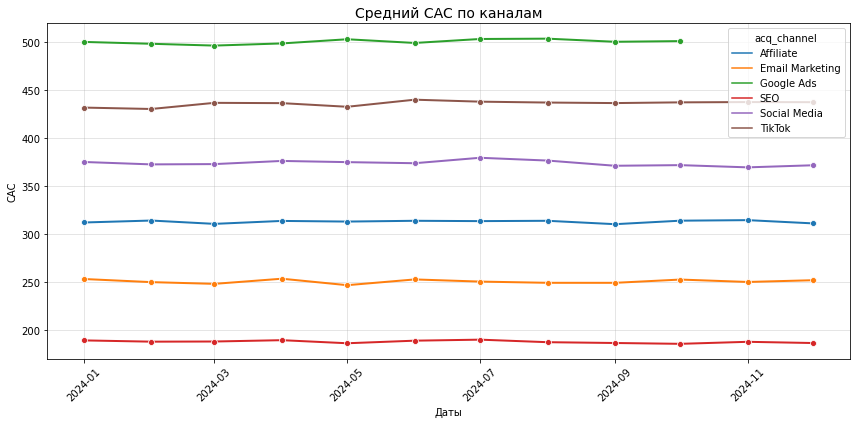

In [86]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi_cohort_by_channel, 
    x = 'cohort_date', 
    y = 'avg_cac', 
    hue = 'acq_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('CAC')
plt.title('Средний CAC по каналам', fontsize = 14)

plt.tight_layout()
plt.show()

Стоимость привлечения внутри каждого канала в течение 2024 года была относительно стабильной.

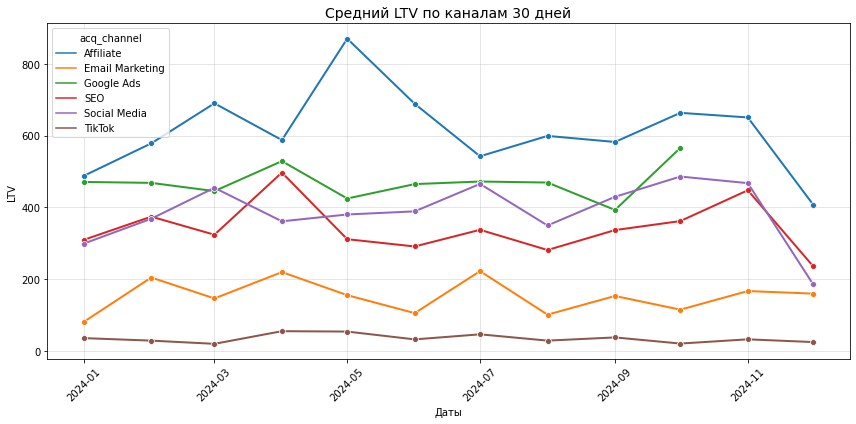

In [87]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi_cohort_by_channel, 
    x = 'cohort_date', 
    y = 'avg_ltv_30d', 
    hue = 'acq_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('LTV')
plt.title('Средний LTV по каналам 30 дней', fontsize = 14)

plt.tight_layout()
plt.show()

Больше всего денег приносят `Affiliate` `Email` `Google Ads` и `SEO`, у них стабильная динамика, графики постепенно растут. Самый слабый канал - `TikTok`.

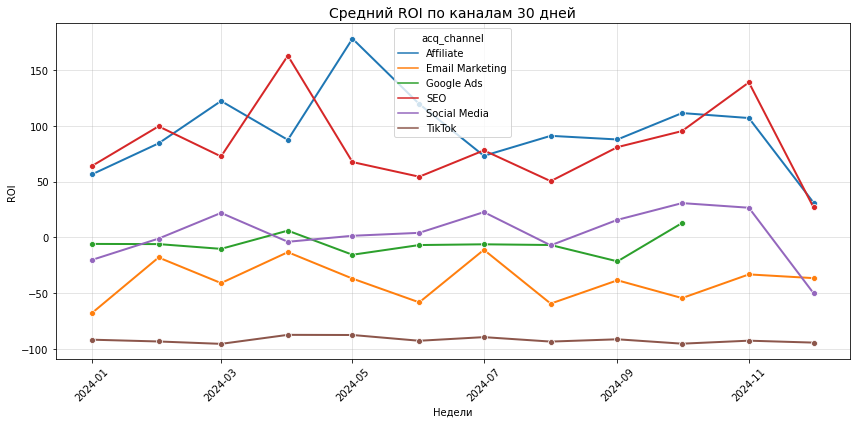

In [88]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi_cohort_by_channel, 
    x = 'cohort_date', 
    y = 'roi_percent', 
    hue = 'acq_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)

plt.xlabel('Недели')
plt.ylabel('ROI')
plt.title('Средний ROI по каналам 30 дней', fontsize = 14)

plt.tight_layout()
plt.show()

Эффективность каналов привлечения очень разная. Стабильно выше 0 метрика ROI только у `Affiliate` и `SEO`. Еле еле несколько месяцев в году выше 0 каналы `Google Ads` и `Social Media`. Наиболее низкий ROI у `TikTok`, при этом расходы на него существенно выросли с лета. Возможно, этот канал мог способствовать снижению общей эффективности маркетинговых инвестиций.

In [89]:
budget_by_channel = (
    df_costs
    .groupby('acq_channel')['budget']
    .sum()
    .reset_index(name = 'total_budget')
)

users_by_channel = (
    df_users
    .groupby('acq_channel')['user_id']
    .nunique()
    .reset_index(name = 'users_count')
)

channel_summary = budget_by_channel.merge(
    users_by_channel,
    on = 'acq_channel',
    how = 'left'
)

channel_summary['budget_share'] = (
    channel_summary['total_budget'] /
    channel_summary['total_budget'].sum() * 100
)

channel_summary['users_share'] = (
    channel_summary['users_count'] /
    channel_summary['users_count'].sum() * 100
)

channel_summary['budget_users_ratio'] = (
    channel_summary['budget_share'] /
    channel_summary['users_share']
)

channel_table = channel_summary[['acq_channel', 'budget_share', 'users_share', 'budget_users_ratio']].copy()

channel_table['budget_share'] = channel_table['budget_share'].round(1)
channel_table['users_share'] = channel_table['users_share'].round(1)
channel_table['budget_users_ratio'] = channel_table['budget_users_ratio'].round(2)

channel_table

,acq_channel,budget_share,users_share,budget_users_ratio
0,Affiliate,10.4,13.7,0.76
1,Direct,0.6,NaN,NaN
2,Email Marketing,2.8,4.6,0.60
3,Google Ads,24.1,21.1,1.14
4,SEO,3.4,7.5,0.46
5,Social Media,8.5,9.5,0.90
6,TikTok,50.2,43.6,1.15


Рост стоимости привлечения не коррелирует с качеством пользователей. `TikTok` приводит много пользователей, но они не монетизируются, при этом ест половину маркетингового бюджета. Каналы `Affiliate` и `SEO` получают меньшую долю бюджета, но показывают хороший средний LTV относительно CAC.

In [90]:
user_metrics = df_users[['user_id', 'cohort_month', 'acq_channel']].copy()
buyers = set(df_orders['user_id'])
user_metrics['is_buyer'] = user_metrics['user_id'].isin(buyers)

conversion_by_channel = (
    user_metrics
    .groupby('acq_channel')
    .agg(
        users = ('user_id', 'nunique'),
        buyers = ('is_buyer', 'sum')
    )
    .reset_index()
)

conversion_by_channel['conversion'] = (
    conversion_by_channel['buyers'] /
    conversion_by_channel['users'] * 100
)

conversion_by_channel

,acq_channel,users,buyers,conversion
0,Affiliate,6069,2338,38.523645
1,Email Marketing,2044,325,15.900196
2,Google Ads,9319,3187,34.198948
3,SEO,3312,874,26.388889
4,Social Media,4179,1211,28.978224
5,TikTok,19228,719,3.739338


`TikTok` приводит больше всех пользователей, которые практически не конвертируются в покупателей. Почти все отваливаются на каком-то этапе.

In [91]:
df_events_channel = df_events.merge(
    df_users[['user_id', 'acq_channel']],
    on = 'user_id',
    how = 'left'
)

df_tiktok_events = df_events_channel[
    (df_events_channel['acq_channel'] == 'TikTok') &
    (df_events_channel['event_type'].isin(steps))
]

df_tiktok_counts = (
    df_tiktok_events
    .groupby('event_type')['user_id']
    .nunique()
    .reindex(steps)
)

funnel_tiktok = pd.DataFrame({
    'step': df_tiktok_counts.index,
    'users': df_tiktok_counts.values
})

first_users = funnel_tiktok.loc[0, 'users']

funnel_tiktok['conversion_from_first_%'] = (
    funnel_tiktok['users'] / first_users * 100
).round(1)

funnel_tiktok['conversion_from_previous_%'] = (
    funnel_tiktok['users'] /
    funnel_tiktok['users'].shift(1) * 100
).round(1)

funnel_tiktok

,step,users,conversion_from_first_%,conversion_from_previous_%
0,page_view,6651,100.0,NaN
1,product_view,6631,99.7,99.7
2,product_click,6438,96.8,97.1
3,add_to_cart,5649,84.9,87.7
4,checkout_start,3849,57.9,68.1
5,checkout_complete,2633,39.6,68.4


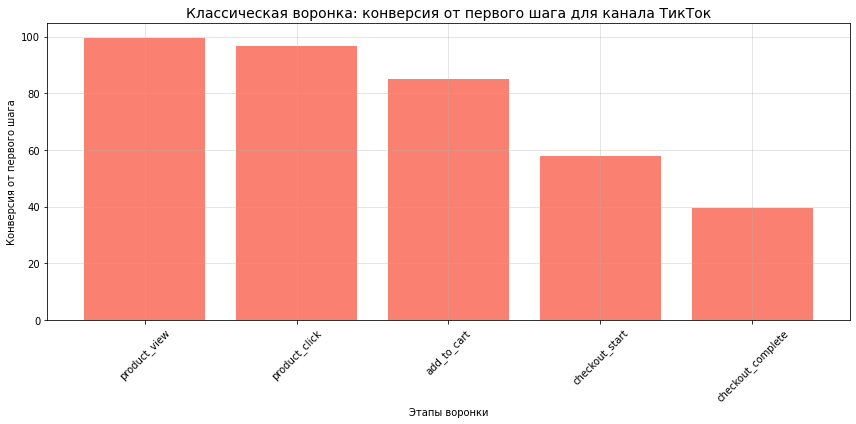

In [92]:
plt.figure(figsize = (12, 6))

plot_df_funnel_tiktok = funnel_tiktok.iloc[1:]

plt.bar(
    plot_df_funnel_tiktok['step'], 
    plot_df_funnel_tiktok['conversion_from_first_%'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Классическая воронка: конверсия от первого шага для канала ТикТок', fontsize = 14)
plt.ylabel('Конверсия от первого шага')
plt.xlabel('Этапы воронки')

plt.tight_layout()
plt.show()

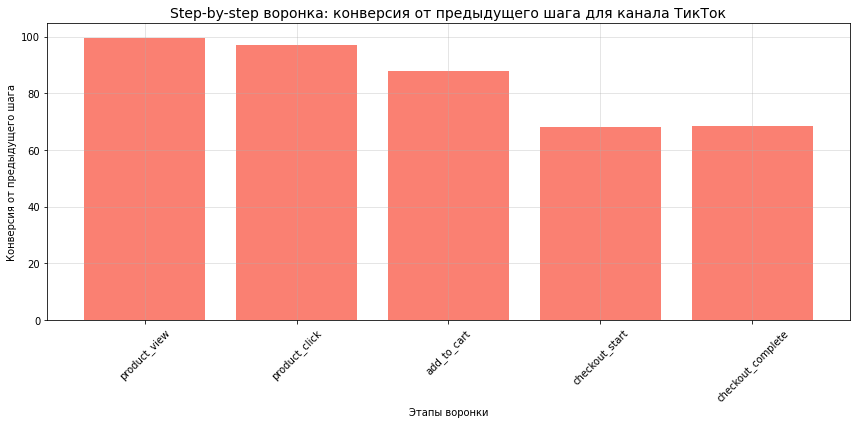

In [93]:
plt.figure(figsize = (12, 6))

plot_df_funnel_tiktok_p = funnel_tiktok.iloc[1:]

plt.bar(
    plot_df_funnel_tiktok_p['step'], 
    plot_df_funnel_tiktok_p['conversion_from_previous_%'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Step-by-step воронка: конверсия от предыдущего шага для канала ТикТок', fontsize = 14)
plt.ylabel('Конверсия от предыдущего шага')
plt.xlabel('Этапы воронки')

plt.tight_layout()
plt.show()

Чекаут - самое слабое место.

In [94]:
events_with_channel = df_events.merge(df_users[['user_id', 'acq_channel']], on = 'user_id', how = 'left')

comparison = (
    events_with_channel
    .groupby(['acq_channel', 'event_type'])['user_id']
    .nunique()
    .reset_index(name = 'users')
)

channel_users = (
    df_users
    .groupby('acq_channel')['user_id']
    .nunique()
    .reset_index(name = 'channel_users')
)

comparison = comparison.merge(channel_users,  on = 'acq_channel', how = 'left')
comparison['user_share_%'] = (comparison['users'] / comparison['channel_users'] * 100).round(1)

behavior_comparison = comparison[
    comparison['event_type'].isin([
        'search',
        'filter_apply',
        'category_view',
        'wishlist_add',
        'banner_click',
        'promo_view'
    ])].pivot(index = 'event_type', columns = 'acq_channel', values = 'user_share_%'
).round(1)

behavior_comparison

acq_channel,Affiliate,Email Marketing,Google Ads,SEO,Social Media,TikTok
event_type,,,,,,
banner_click,26.8,29.6,25.7,33.1,18.3,7.9
category_view,27.4,30.9,26.2,32.9,19.6,7.8
filter_apply,28.1,30.6,26.6,33.4,19.5,7.6
promo_view,27.2,30.8,26.0,32.9,17.8,7.6
search,27.8,30.1,25.9,33.5,18.3,7.5
wishlist_add,27.2,29.0,25.6,32.9,18.4,7.3


Пользователи, привлечённые из `TikTok`, хуже всего показывают себя в дополнительных действиях. Они не только реже доходят до чекаута, но и слабо исследуют маркетплейс. 

Поищем другие инсайты.

In [95]:
segment_channel = pd.crosstab(
    df_users['acq_channel'],
    df_users['buyer_segment'],
    normalize='index'
) * 100

segment_channel

buyer_segment,medium,one_time,rare,regular
acq_channel,,,,
Affiliate,37.188993,15.653320,29.593014,17.564673
Email Marketing,36.203523,14.432485,30.577299,18.786693
Google Ads,37.589870,15.430840,29.649104,17.330186
SEO,38.103865,13.768116,30.163043,17.964976
Social Media,36.994496,15.171094,30.725054,17.109356
TikTok,36.992927,15.227793,30.107135,17.672145


In [96]:
bins = [0, 24, 34, 44, 54, 100]
labels = ['18-24', '25-34', '35-44', '45-54', '55+']

df_users['age_group'] = pd.cut(
    df_users['age'],
    bins = bins,
    labels = labels
)

age_channel = pd.crosstab(
    df_users['acq_channel'],
    df_users['age_group'],
    normalize = 'index'
) * 100

age_channel

age_group,18-24,25-34,35-44,45-54,55+
acq_channel,,,,,
Affiliate,13.593673,18.322623,19.294777,18.718075,30.070852
Email Marketing,13.356164,18.639922,19.618395,18.542074,29.843444
Google Ads,13.445649,18.907608,19.014916,19.250993,29.380835
SEO,12.318841,19.353865,19.233092,18.357488,30.736715
Social Media,13.567839,19.717636,18.473319,18.425461,29.815745
TikTok,12.991471,18.821510,18.821510,18.821510,30.543998


In [97]:
region_channel = pd.crosstab(
    df_users['region'],
    df_users['acq_channel'],
    normalize = 'index'
) * 100

region_channel

acq_channel,Affiliate,Email Marketing,Google Ads,SEO,Social Media,TikTok
region,,,,,,
Другие регионы,13.798567,4.491595,21.486635,7.019840,9.892532,43.310829
Екатеринбург,13.100233,4.475524,19.673660,7.925408,10.163170,44.662005
Краснодар,13.376252,5.436338,22.031474,8.369099,8.941345,41.845494
Москва,13.687380,4.507711,20.923442,7.810932,9.635916,43.434620
Московская область,13.553114,4.959143,20.653705,8.086785,8.875740,43.871513
Нижний Новгород,13.958810,4.462243,20.652174,8.237986,9.153318,43.535469
Новосибирск,13.232734,4.643064,20.197330,7.138712,7.719095,47.069066
Ростов-на-Дону,12.860155,4.356992,22.487702,7.449051,9.276177,43.569923
Санкт-Петербург,14.379671,4.932735,21.150972,7.324365,9.028401,43.183857


In [98]:
gender_channel = pd.crosstab(
    df_users['acq_channel'],
    df_users['gender'],
    normalize = 'index'
) * 100

gender_channel

gender,F,M
acq_channel,,
Affiliate,49.826990,50.173010
Email Marketing,49.461840,50.538160
Google Ads,50.338019,49.661981
SEO,49.607488,50.392512
Social Media,51.040919,48.959081
TikTok,50.052007,49.947993


Разница по группам и каналам совсем небольшая - 1-2%.

In [99]:
orders_users = df_orders.merge(
    df_users[['user_id', 'age', 'gender', 'region', 'acq_channel', 'buyer_segment']],
    on = 'user_id',
    how = 'left'
)

segment_revenue = (
    orders_users
    .groupby('buyer_segment')
    .agg(
        users = ('user_id', 'nunique'),
        orders = ('order_id', 'nunique'),
        revenue = ('total_price', 'sum')
    )
    .reset_index()
)

segment_revenue['revenue_share_%'] = (segment_revenue['revenue'] / segment_revenue['revenue'].sum() * 100).round(1)
segment_revenue

,buyer_segment,users,orders,revenue,revenue_share_%
0,medium,3692,7528,1.038102e+08,24.3
1,one_time,258,345,4.421034e+06,1.0
2,rare,988,1501,2.093820e+07,4.9
3,regular,3716,21072,2.978088e+08,69.7


Меньше всего людей останавливаются на одной покупке. Пользователи, покупающие регулярно, приносят две трети дохода. 

In [100]:
orders_users['age_group'] = pd.cut(orders_users['age'], bins = bins, labels = labels)

age_revenue = (
    orders_users
    .groupby('age_group', observed=True)
    .agg(
        users = ('user_id', 'nunique'),
        orders = ('order_id', 'nunique'),
        revenue = ('total_price', 'sum')
    )
    .reset_index()
)

age_revenue['revenue_share_%'] = (age_revenue['revenue'] /age_revenue['revenue'].sum() * 100).round(1)

age_revenue

,age_group,users,orders,revenue,revenue_share_%
0,18-24,1158,4146,5.698679e+07,13.3
1,25-34,1644,6160,9.176606e+07,21.5
2,35-44,1702,5825,8.129561e+07,19.0
3,45-54,1630,5478,7.303666e+07,17.1
4,55+,2520,8837,1.238931e+08,29.0


Самая слабая возрастная группа - до 24 лет.

In [101]:
category_revenue = (
    df_orders
    .groupby('category_name')
    .agg(
        orders = ('order_id', 'nunique'),
        buyers = ('user_id', 'nunique'),
        quantity = ('quantity', 'sum'),
        revenue = ('total_price', 'sum')
    )
    .reset_index()
)

category_revenue['revenue_share_%'] = (category_revenue['revenue'] / category_revenue['revenue'].sum() * 100).round(1)

category_revenue

,category_name,orders,buyers,quantity,revenue,revenue_share_%
0,Автотовары,1043,561,2123,20896434.84,4.7
1,Аксессуары для гаджетов,1255,726,2547,13869405.42,3.2
2,Бытовая техника,1030,546,2059,44978661.11,10.2
3,Декор и освещение,1053,538,2089,14076071.35,3.2
4,Детская одежда,1421,942,2880,6426106.06,1.5
5,Детские игрушки,1131,558,2191,8701776.00,2.0
6,Женская одежда,1191,646,2419,13746700.97,3.1
7,Зоотовары,1396,888,2820,7451679.28,1.7
8,Инструменты и садовый инвентарь,1000,501,2003,16247455.74,3.7
9,Книги и канцтовары,1316,739,2620,4088868.74,0.9


Самые успешные категории: мебель для дома, бытовая техника, украшения и часы.

In [102]:
top_products = (
    df_orders
    .groupby('product_name')
    .agg(
        orders = ('order_id', 'nunique'),
        buyers = ('user_id', 'nunique'),
        quantity = ('quantity', 'sum'),
        revenue = ('total_price', 'sum')
    )
    .reset_index()
    .sort_values('revenue', ascending = False)
)

top_products.head(15)

,product_name,orders,buyers,quantity,revenue
41,Диван угловой,118,108,250,15983095.00
172,Тумба ТВ,132,115,250,11517802.09
163,Стол обеденный,117,101,238,9659908.30
80,Кровать двуспальная,100,84,201,9399451.11
195,Шкаф-купе,125,105,235,8028617.55
188,Часы Casio,154,126,323,7907802.28
66,Комод с ящиками,116,104,238,7772106.58
179,Фен для волос,122,106,246,7744476.06
185,Цепочка серебряная,136,109,269,7169909.86
137,Пылесос робот,151,123,310,6678230.80


Мебель, украшения, бытовая техника - самые популярные товары. 

In [103]:
age_by_channel = pd.crosstab(
    df_users['age_group'],
    df_users['acq_channel'],
    normalize = 'columns'
) * 100

age_by_channel

acq_channel,Affiliate,Email Marketing,Google Ads,SEO,Social Media,TikTok
age_group,,,,,,
18-24,13.593673,13.356164,13.445649,12.318841,13.567839,12.991471
25-34,18.322623,18.639922,18.907608,19.353865,19.717636,18.821510
35-44,19.294777,19.618395,19.014916,19.233092,18.473319,18.821510
45-54,18.718075,18.542074,19.250993,18.357488,18.425461,18.821510
55+,30.070852,29.843444,29.380835,30.736715,29.815745,30.543998


Получается распределение по возрастным группам равномерное для всех каналов привлечения, и оно перевешивает в сторону более возрастных потребителей. Самые прибыльные товары конечно дорогие, но может одежда/обувь/книги/декор/канцтовары и т.д. как раз и не растут в доходах из-за странного таргета аудитории. Украшения и часы, например, составляют крупную долю в прибыли.

`TikTok` приводит большой объём пользователей, но большая часть из них не становится активными платящими клиентами. Бюджет распределён не пропорционально эффективности каналов. Возможно нужно перераспределение бюджета в пользу каналов с более высоким LTV/CAC, например `Affiliate` и `SEO`. `Google Ads` работал не так плохо в первой половину года. `Social Media` находится около точки безубыточности. 

## Выводы по этапу 5

Можно предположить, что увеличение маркетинговых инвестиций во второй половине 2014 года не привело к пропорциональному росту качества привлечённых пользователей и не повысило прибыль с комиссии.

Самый проблемный канал привлечения - `TikTok`. Привлекает много аудитории, но она слабо конвертируется в покупки и приносит существенно меньше выручки. Лучше всего работают `Affiliate`, `SEO` и `Google Ads`. У всех каналов есть перекос на более возрастную аудиторию, возможно более точечное таргетирование с разделением по  вазрасту и интересам привело бы к более высокой конвертации в продукт.

Наиболее значимый сегмент по выручке — regular, это основной источник монетизации. Можно изучить, как переводить больше пошльзователей в эту группу. Наибольшую долю выручки формируют: мебель для дома, бытовая техника, украшения и часы, спортивный инвентарь и товары для туризма.


Гипотезы:
- Если перераспределить часть рекламного бюджета `TikTok` на `Email Marketing`, `Google Ads` и `Social Media`, то окупаемость затрат на привлечение и удержание пользователей вырастет (сейчас `TikTok` самый неэффективный канал по соотношению затрат/выгоды, а каналы `Email Marketing`, `Google Ads` и `Social Media` находтся около линии окупаемости).
- Если масштабировать и увеличить бюджет для каналов `Affiliate` и `SEO` за счёт менее эффективных источников, то можно увеличить объём выручки без пропорционального роста затрат.
- Если уделить дополнительное внимание `medium` пользователям (персонализированные рекомендаций, скидки, акции), то они вероятнее перейдут в группу `regular` и принесут больше комиссии платформе.
- Если скорректировать таргет рекламных компаний и источников привлечения на более молодую аудиторию + категории товара мелкого и среднего сегмента, то можно увеличить конвертацию в покупку у пользователей до 35 лет и повысить возвращаемость новых когорт.
-------

## Подготовка эксперимента и подведение его результатов

Команда продукта рассмотрела гипотезы и решила влиять на конверсию при помощи финансовых стимуляций. Так как ситуация со снижением выручки срочная и безотлагательная, подготовили дизайн документа, проведём эксперимент.

Загрузим данные с результатами эксперимента, проверим корректность теста.

In [104]:
df_orders_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders_AB.csv', parse_dates = ['order_date','order_week','order_month'])
df_split_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_AB_split_users.csv')
df_users_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users_AB.csv', parse_dates = ['registration_date','cohort_week','cohort_month'])
df_events_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events_AB.csv', parse_dates = ['event_date','event_week','event_month'])

In [105]:
df_split_ab.head()

,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control


In [106]:
df_split_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB


In [107]:
df_split_ab['group'].value_counts()

control      1503
treatment    1465
Name: group, dtype: int64

In [108]:
df_abt_group_cont = df_split_ab[df_split_ab['group'] == 'control']['user_id'].unique()
df_abt_group_test = df_split_ab[df_split_ab['group'] == 'treatment']['user_id'].unique()

df_abt_inter = set(df_abt_group_cont).intersection(set(df_abt_group_test))
df_abt_inter

set()

Пересечений групп пользователей нет.

In [109]:
df_split_ab.duplicated().sum()

0

In [110]:
df_split_ab['user_id'].nunique()

2968

In [111]:
test_group = df_split_ab.groupby('group')['user_id'].nunique()
test_group

part_group_cont = test_group['control']
part_group_test = test_group['treatment']

P = round(100 * abs(part_group_cont - part_group_test) / part_group_cont, 2)
P

2.53

Разница численности групп меньше 3%.

In [112]:
df_users_ab.head()

,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,49,M,Екатеринбург,TikTok,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,50,M,Санкт-Петербург,TikTok,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,60,F,Москва,TikTok,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,31,M,Екатеринбург,TikTok,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,44,M,Санкт-Петербург,TikTok,rare,2024-01-01,2024-01-01


In [113]:
df_users_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            22196 non-null  int64         
 1   registration_date  22196 non-null  datetime64[ns]
 2   age                22196 non-null  int64         
 3   gender             22196 non-null  object        
 4   region             22196 non-null  object        
 5   acq_channel        22196 non-null  object        
 6   buyer_segment      22196 non-null  object        
 7   cohort_week        22196 non-null  datetime64[ns]
 8   cohort_month       22196 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 1.5+ MB


In [114]:
df_users_ab['acq_channel'].value_counts()

TikTok    22196
Name: acq_channel, dtype: int64

In [115]:
df_users_ab_test = df_split_ab.merge(
    df_users_ab,
    on = 'user_id',
    how = 'left',
    validate = 'one_to_one'
)

In [116]:
df_users_ab_test.head()

,user_id,group,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,44965,control,2025-01-01 18:10:00,66,M,Новосибирск,TikTok,one_time,2024-12-30,2025-01-01
1,44967,control,2025-01-01 11:29:00,70,M,Московская область,TikTok,rare,2024-12-30,2025-01-01
2,44968,control,2025-01-01 13:05:00,68,F,Нижний Новгород,TikTok,regular,2024-12-30,2025-01-01
3,44969,treatment,2025-01-01 00:23:00,24,F,Краснодар,TikTok,medium,2024-12-30,2025-01-01
4,44970,control,2025-01-01 06:33:00,50,M,Санкт-Петербург,TikTok,regular,2024-12-30,2025-01-01


In [117]:
df_users_ab_test.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2968 entries, 0 to 2967
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            2968 non-null   int64         
 1   group              2968 non-null   object        
 2   registration_date  2968 non-null   datetime64[ns]
 3   age                2968 non-null   int64         
 4   gender             2968 non-null   object        
 5   region             2968 non-null   object        
 6   acq_channel        2968 non-null   object        
 7   buyer_segment      2968 non-null   object        
 8   cohort_week        2968 non-null   datetime64[ns]
 9   cohort_month       2968 non-null   datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(5)
memory usage: 255.1+ KB


In [118]:
df_users_ab_test['cohort_week'].min()

Timestamp('2024-12-30 00:00:00')

In [119]:
df_users_ab_test['cohort_week'].max()

Timestamp('2025-01-20 00:00:00')

In [120]:
df_users_ab_test['registration_date'].min()

Timestamp('2025-01-01 00:05:00')

In [121]:
df_users_ab_test['registration_date'].max()

Timestamp('2025-01-26 23:41:00')

In [122]:
df_orders_ab.head()

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


In [123]:
df_orders_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33280 entries, 0 to 33279
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       33280 non-null  int64         
 1   user_id        33280 non-null  int64         
 2   order_date     33280 non-null  datetime64[ns]
 3   product_name   33280 non-null  object        
 4   quantity       33280 non-null  int64         
 5   unit_price     33280 non-null  float64       
 6   total_price    33280 non-null  float64       
 7   category_name  33280 non-null  object        
 8   order_week     33280 non-null  datetime64[ns]
 9   order_month    33280 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.5+ MB


In [124]:
df_orders_ab_test = df_orders_ab.merge(
    df_split_ab,
    on = 'user_id',
    how = 'inner',
    validate = 'many_to_one'
)

In [125]:
df_orders_ab_test.head()

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month,group
0,37141,45065,2025-01-01 11:57:43,Цепочка серебряная,3,7202.01,21606.03,Украшения и часы,2024-12-30,2025-01-01,treatment
1,37148,45081,2025-01-01 16:01:22,Куртка детская,2,2156.91,4313.82,Детская одежда,2024-12-30,2025-01-01,treatment
2,37149,45081,2025-01-01 16:01:22,Джинсы детские,1,873.16,873.16,Детская одежда,2024-12-30,2025-01-01,treatment
3,37147,45077,2025-01-02 04:59:13,Корм для кошек,2,851.39,1702.78,Зоотовары,2024-12-30,2025-01-01,treatment
4,37146,45077,2025-01-02 04:59:13,Чай черный,2,239.45,478.90,Продукты питания,2024-12-30,2025-01-01,treatment


In [126]:
users_in_orders_after_merge = df_orders_ab_test['user_id'].nunique()
users_in_orders_after_merge

126

Заказы совершили только 126 пользователей из 2968.

In [127]:
df_orders_ab_test.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       255 non-null    int64         
 1   user_id        255 non-null    int64         
 2   order_date     255 non-null    datetime64[ns]
 3   product_name   255 non-null    object        
 4   quantity       255 non-null    int64         
 5   unit_price     255 non-null    float64       
 6   total_price    255 non-null    float64       
 7   category_name  255 non-null    object        
 8   order_week     255 non-null    datetime64[ns]
 9   order_month    255 non-null    datetime64[ns]
 10  group          255 non-null    object        
dtypes: datetime64[ns](3), float64(2), int64(3), object(3)
memory usage: 23.9+ KB


In [128]:
df_orders_ab_test['order_date'].min()

Timestamp('2025-01-01 11:57:43')

In [129]:
df_orders_ab_test['order_date'].max()

Timestamp('2025-01-26 20:39:35')

In [130]:
df_orders_ab_test['category_name'].value_counts()

Продукты питания                   32
Детская одежда                     18
Мебель для дома                    14
Инструменты и садовый инвентарь    14
Обувь женская                      14
Зоотовары                          13
Товары для туризма                 12
Одежда для спорта                  11
Автотовары                         11
Медицинские товары                 11
Бытовая техника                    10
Обувь мужская                      10
Декор и освещение                   9
Товары для новорожденных            9
Спортивный инвентарь                8
Товары для кухни                    8
Сумки и аксессуары                  8
Косметика и парфюмерия              8
Украшения и часы                    8
Средства для ухода                  6
Детские игрушки                     6
Мужская одежда                      4
Книги и канцтовары                  4
Женская одежда                      4
Аксессуары для гаджетов             3
Name: category_name, dtype: int64

In [131]:
df_orders_ab_test['product_name'].value_counts()

Мука пшеничная      6
Куртка детская      6
Сахар белый         5
Консервы мясные     5
Чай черный          5
                   ..
Кроссовки Nike      1
Набор ножей         1
Мультиварка         1
Клатч вечерний      1
Стеллаж для книг    1
Name: product_name, Length: 141, dtype: int64

In [132]:
df_orders_ab_test['group'].value_counts()

treatment    231
control       24
Name: group, dtype: int64

In [133]:
df_orders_ab_test['unit_price'].describe()

count      255.000000
mean      7916.605412
std       9347.480591
min        218.820000
25%       1738.445000
50%       5120.850000
75%      10095.410000
max      59299.140000
Name: unit_price, dtype: float64

In [134]:
df_orders_ab_test['total_price'].describe()

count       255.000000
mean      16564.587961
std       22005.800776
min         218.820000
25%        2778.590000
50%        8171.300000
75%       21953.740000
max      168032.340000
Name: total_price, dtype: float64

In [135]:
df_events_ab.head()

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01 15:23:56,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01 15:24:01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01 15:24:10,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


In [136]:
df_events_ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831231 entries, 0 to 831230
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      831231 non-null  int64         
 1   user_id       831231 non-null  int64         
 2   event_date    831231 non-null  datetime64[ns]
 3   event_type    831231 non-null  object        
 4   os            831231 non-null  object        
 5   device        831231 non-null  object        
 6   product_name  409054 non-null  object        
 7   event_week    831231 non-null  datetime64[ns]
 8   event_month   831231 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 57.1+ MB


In [137]:
df_test_events_test = df_events_ab.merge(
    df_split_ab,
    on = 'user_id',
    how = 'inner',
    validate = 'many_to_one'
)

In [138]:
df_test_events_test.head()

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month,group
0,844987,45076,2025-01-02 03:25:32,page_view,Android,tablet,NaN,2024-12-30,2025-01-01,control
1,844988,45076,2025-01-02 03:25:49,product_view,Android,tablet,Картина маслом,2024-12-30,2025-01-01,control
2,844989,45076,2025-01-02 03:26:23,product_click,Android,tablet,Сумка кожаная,2024-12-30,2025-01-01,control
3,844990,45076,2025-01-02 03:26:50,add_to_cart,Android,tablet,Дезодорант,2024-12-30,2025-01-01,control
4,844991,45076,2025-01-02 03:27:11,checkout_start,Android,tablet,NaN,2024-12-30,2025-01-01,control


In [139]:
df_test_events_test.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4349 entries, 0 to 4348
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   event_id      4349 non-null   int64         
 1   user_id       4349 non-null   int64         
 2   event_date    4349 non-null   datetime64[ns]
 3   event_type    4349 non-null   object        
 4   os            4349 non-null   object        
 5   device        4349 non-null   object        
 6   product_name  2335 non-null   object        
 7   event_week    4349 non-null   datetime64[ns]
 8   event_month   4349 non-null   datetime64[ns]
 9   group         4349 non-null   object        
dtypes: datetime64[ns](3), int64(2), object(5)
memory usage: 373.7+ KB


In [140]:
df_test_events_test['user_id'].value_counts()

45643    40
45631    36
44971    33
48593    31
45824    29
         ..
45281     2
47307     2
48694     2
48509     1
47556     1
Name: user_id, Length: 499, dtype: int64

In [141]:
df_test_events_test['event_type'].value_counts()

page_view            812
product_view         807
product_click        752
add_to_cart          603
checkout_start       333
checkout_complete    221
banner_click         104
search               103
user_logout          101
category_view         98
user_login            90
wishlist_add          89
remove_from_cart      84
promo_view            79
filter_apply          73
Name: event_type, dtype: int64

In [142]:
df_test_events_test['product_name'].value_counts()

Шкаф-купе               23
Колготки детские        20
Кроватка детская        20
Ботинки классические    19
Samsung Galaxy Buds     19
                        ..
Велотренажер             5
Чехлы на сиденья         4
Кукла Barbie             4
Миска для корма          4
Настольная игра          3
Name: product_name, Length: 200, dtype: int64

In [143]:
df_test_events_test['device'].value_counts()

tablet     1588
desktop    1496
mobile     1265
Name: device, dtype: int64

In [144]:
df_test_events_test['os'].value_counts()

macOS      1197
Windows    1124
iOS        1097
Android     931
Name: os, dtype: int64

Основная единица анализа — пользователь. Убедиться в том, что их распределение по группам теста не искажает другие показатели.

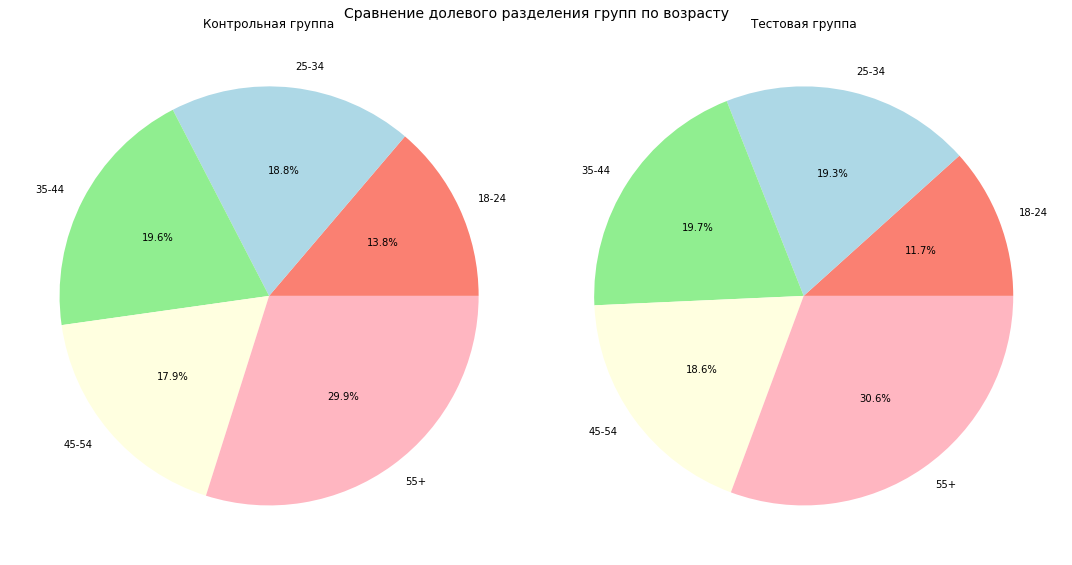

In [145]:
df_users_ab_test['age_group'] = pd.cut(
    df_users_ab_test['age'],
    bins = bins,
    labels = labels
)

plat_cont = (
    df_users_ab_test[df_users_ab_test['group'] == 'control']
    [['user_id', 'age_group']]
    .drop_duplicates(subset = ['user_id'])
    .groupby('age_group', as_index = False)['user_id']
    .nunique()
    .rename(columns = {'user_id': 'count'})
)

plat_test = (
    df_users_ab_test[df_users_ab_test['group'] == 'treatment']
    [['user_id', 'age_group']]
    .drop_duplicates(subset = ['user_id'])
    .groupby('age_group', as_index = False)['user_id']
    .nunique()
    .rename(columns = {'user_id': 'count'})
)

sizes_cont = plat_cont['count'].values
labels_cont = plat_cont['age_group'].values
sizes_test = plat_test['count'].values
labels_test = plat_test['age_group'].values

fig, (c, t) = plt.subplots(1, 2, figsize = (15, 8))

c.pie(
    sizes_cont,
    labels = labels_cont,
    autopct = '%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen', 'lightyellow', 'lightpink']
)

t.pie(
    sizes_test,
    labels = labels_test,
    autopct = '%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen', 'lightyellow', 'lightpink']
)

plt.suptitle('Сравнение долевого разделения групп по возрасту', fontsize = 14)
c.set_title('Контрольная группа')
t.set_title('Тестовая группа')

plt.tight_layout()
plt.show()

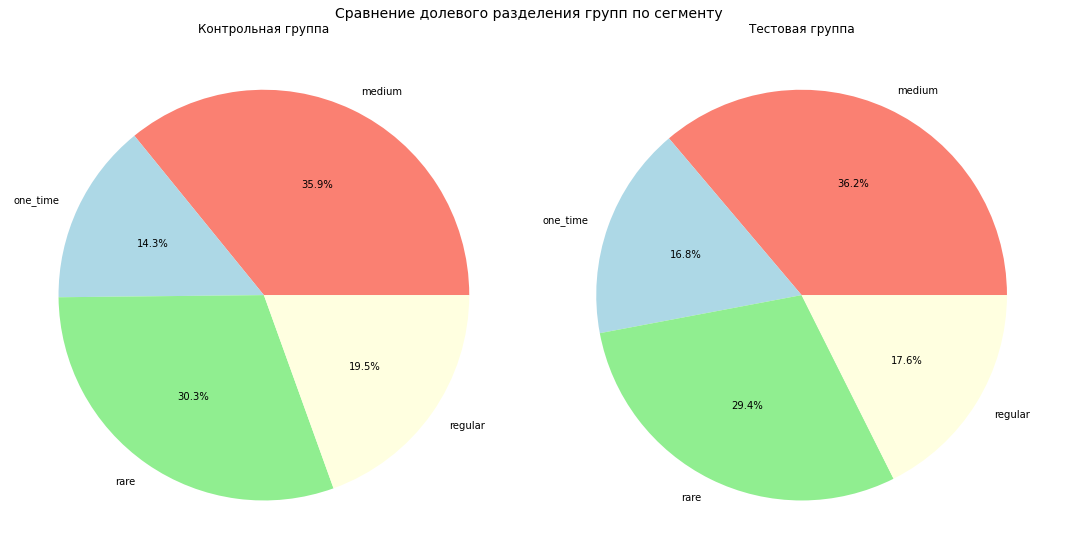

In [146]:
segment_cont = (
    df_users_ab_test[df_users_ab_test['group'] == 'control']
    [['user_id', 'buyer_segment']]
    .drop_duplicates(subset = ['user_id'])
    .groupby('buyer_segment', as_index = False)['user_id']
    .nunique()
    .rename(columns = {'user_id': 'count'})
)

segment_test = (
    df_users_ab_test[df_users_ab_test['group'] == 'treatment']
    [['user_id', 'buyer_segment']]
    .drop_duplicates(subset = ['user_id'])
    .groupby('buyer_segment', as_index = False)['user_id']
    .nunique()
    .rename(columns = {'user_id': 'count'})
)

sizes_cont = segment_cont['count'].values
labels_cont = segment_cont['buyer_segment'].values
sizes_test = segment_test['count'].values
labels_test = segment_test['buyer_segment'].values

fig, (c, t) = plt.subplots(1, 2, figsize=(15, 8))

c.pie(
    sizes_cont,
    labels = labels_cont,
    autopct = '%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen', 'lightyellow']
)

t.pie(
    sizes_test,
    labels = labels_test,
    autopct = '%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen', 'lightyellow']
)

plt.suptitle('Сравнение долевого разделения групп по сегменту', fontsize = 14)
c.set_title('Контрольная группа')
t.set_title('Тестовая группа')

plt.tight_layout()
plt.show()

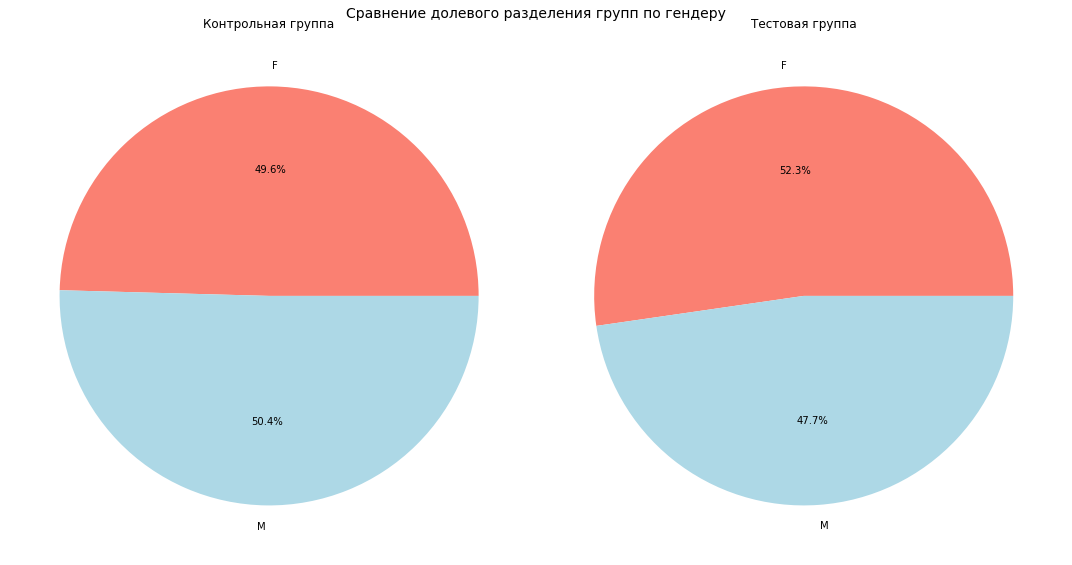

In [147]:
gender_cont = (
    df_users_ab_test[df_users_ab_test['group'] == 'control']
    [['user_id', 'gender']]
    .drop_duplicates(subset = ['user_id'])
    .groupby('gender', as_index = False)['user_id']
    .nunique()
    .rename(columns = {'user_id': 'count'})
)

gender_test = (
    df_users_ab_test[df_users_ab_test['group'] == 'treatment']
    [['user_id', 'gender']]
    .drop_duplicates(subset = ['user_id'])
    .groupby('gender', as_index = False)['user_id']
    .nunique()
    .rename(columns = {'user_id': 'count'})
)

sizes_cont = gender_cont['count'].values.astype(float)
labels_cont = gender_cont['gender'].values
sizes_test = gender_test['count'].values.astype(float)
labels_test = gender_test['gender'].values

fig, (c, t) = plt.subplots(1, 2, figsize = (15, 8))

c.pie(
    sizes_cont,
    labels = labels_cont,
    autopct = '%1.1f%%',
    colors = ['salmon', 'lightblue']
)

t.pie(
    sizes_test,
    labels = labels_test,
    autopct = '%1.1f%%',
    colors = ['salmon', 'lightblue']
)

plt.suptitle('Сравнение долевого разделения групп по гендеру', fontsize = 14)
c.set_title('Контрольная группа')
t.set_title('Тестовая группа')

plt.tight_layout()
plt.show()

Разница в группах по разным срезам до 5%, это приемлемо. Можно сказать, что тест проходит корректно. Различие в количестве пользователей в двух группах незначительное. Выборки независимые, пересечений обнаружено не было. Тест проводится 3 недели.

### Сравнение воронок событий.

Сравним пользовательский путь новых пользователей в тестовой и контрольной группах. Построим классическую и последовательную воронки, выполним визуализацию.

In [148]:
df_test_events_test_cont = df_test_events_test[df_test_events_test['group'] == 'control']
df_test_events_test_test = df_test_events_test[df_test_events_test['group'] == 'treatment']

In [149]:
df_hist_steps_cont = df_test_events_test_cont[df_test_events_test_cont['event_type'].isin(steps)]
df_hist_steps_counts_cont = df_hist_steps_cont.groupby('event_type')['user_id'].nunique().reindex(steps)

funnel_df_hist_cont = pd.DataFrame({
   'step': df_hist_steps_counts_cont.index,
   'users': df_hist_steps_counts_cont.values
})

df_hist_first_step_users_cont = funnel_df_hist_cont.loc[0, 'users']
funnel_df_hist_cont['conversion_from_first_%'] = (funnel_df_hist_cont['users'] / df_hist_first_step_users_cont * 100).round(1)
funnel_df_hist_cont['conversion_from_previous_%'] = (funnel_df_hist_cont['users'] / funnel_df_hist_cont['users'].shift(1) * 100).round(1)

funnel_df_hist_cont

,step,users,conversion_from_first_%,conversion_from_previous_%
0,page_view,258,100.0,NaN
1,product_view,257,99.6,99.6
2,product_click,245,95.0,95.3
3,add_to_cart,211,81.8,86.1
4,checkout_start,126,48.8,59.7
5,checkout_complete,79,30.6,62.7


In [150]:
df_hist_steps_test = df_test_events_test_test[df_test_events_test_test['event_type'].isin(steps)]
df_hist_steps_counts_test = df_hist_steps_test.groupby('event_type')['user_id'].nunique().reindex(steps)

funnel_df_hist_test = pd.DataFrame({
   'step': df_hist_steps_counts_test.index,
   'users': df_hist_steps_counts_test.values
})

df_hist_first_step_users_test = funnel_df_hist_test.loc[0, 'users']
funnel_df_hist_test['conversion_from_first_%'] = (funnel_df_hist_test['users'] / df_hist_first_step_users_test * 100).round(1)
funnel_df_hist_test['conversion_from_previous_%'] = (funnel_df_hist_test['users'] / funnel_df_hist_test['users'].shift(1) * 100).round(1)

funnel_df_hist_test

,step,users,conversion_from_first_%,conversion_from_previous_%
0,page_view,232,100.0,NaN
1,product_view,230,99.1,99.1
2,product_click,225,97.0,97.8
3,add_to_cart,193,83.2,85.8
4,checkout_start,128,55.2,66.3
5,checkout_complete,85,36.6,66.4


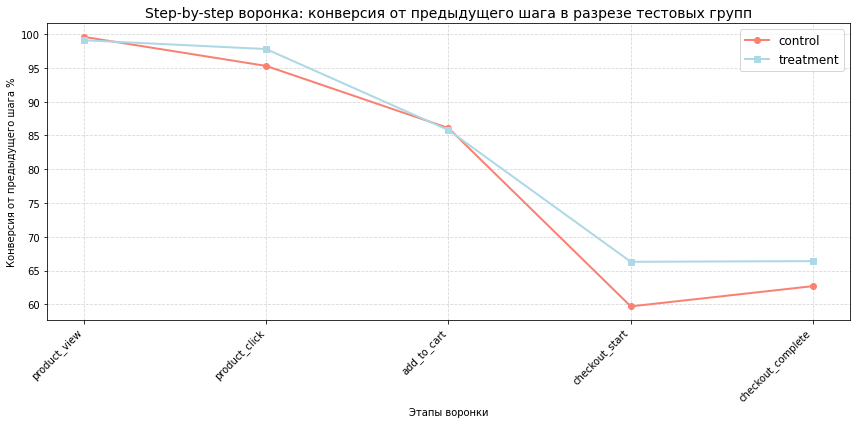

In [151]:
plt.figure(figsize = (12, 6))

plt.plot(
    funnel_df_hist_cont['step'],
    funnel_df_hist_cont['conversion_from_previous_%'],
    marker = 'o',
    linestyle = '-',
    color = 'salmon',
    linewidth = 2,
    label = 'control'
)

plt.plot(
    funnel_df_hist_test['step'],
    funnel_df_hist_test['conversion_from_previous_%'],
    marker = 's',
    linestyle = '-',
    color = 'lightblue',
    linewidth = 2,
    label = 'treatment'
)

plt.title('Step-by-step воронка: конверсия от предыдущего шага в разрезе тестовых групп', fontsize = 14)
plt.xlabel('Этапы воронки')
plt.ylabel('Конверсия от предыдущего шага %')

plt.legend(fontsize = 12)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.xticks(rotation = 45, ha = 'right')

plt.tight_layout()
plt.show()

В тестовой группе конверсия воронки намного лучше, чем в контрольной. Количество пользователей, которые доходят до этапа чекаута выше на 6%, а заканчивают покупку на 4% больше людей.

### Дизайн эксперимента: Бонус на первую покупку для пользователей TikTok

Бизнес-контекст: Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.

Цель: Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.

Гипотеза: Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку.

**Формат эксперимента**

Тип эксперимента: Сплит-роллинг (rolling split). Канал: Только пользователи, пришедшие с TikTok. Группы: Контрольная (A): пользователи TikTok без бонуса, тестовая (B): пользователи TikTok с бонусом на первую покупку. Распределение: Равномерное распределение новых пользователей TikTok между группами по дате регистрации. Период проведения: 3 недели (фиксировано)

**Ключевые метрики**

Основная метрика: Конверсия в первую покупку — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку. Цель: увеличить конверсию с помощью бонуса. Критерий успеха: статистически значимый рост конверсии в тестовой группе.

Вспомогательные метрики: ARPU (средняя выручка на пользователя TikTok). ARPPU (средняя выручка на покупателя TikTok). AOV (средний чек TikTok).

Барьерная метрика: Общая выручка от пользователей TikTok.

**Размеры групп и запуск**

Целевая аудитория: только пользователи TikTok. 
Размеры групп: определяются по фактическому трафику TikTok за период эксперимента.
Комментарий: запуск без предварительного расчёта мощности и MDE из-за срочности задачи.

----

Начнём с основной метрики. Будем использовать z-тест для долей конверсии, уровень значимости стандартный α = 0.05 и сделаем поправку на окно в 3 недели.

H0 - Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, не приведет к увеличению конверсии в первую покупку.

H1 - Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку.

In [152]:
ab_users = df_split_ab['user_id'].unique()
df_abt = df_users_ab[df_users_ab['user_id'].isin(ab_users)].copy()

df_abt = df_abt.merge(
    df_split_ab[['user_id', 'group']],
    on = 'user_id',
    how = 'left',
    validate=  'one_to_one'
)

orders = df_orders_ab[df_orders_ab['user_id'].isin(ab_users)].copy()

orders = orders.merge(
    df_split_ab[['user_id', 'group']],
    on = 'user_id',
    how = 'left',
    validate = 'many_to_one'
)

orders = orders.merge(
    df_abt[['user_id', 'registration_date']],
    on = 'user_id',
    how = 'left',
    validate = 'many_to_one'
)

orders['days_after_registration'] = (orders['order_date'] - orders['registration_date']).dt.days
orders_21d = orders[(orders['days_after_registration'] >= 0) & (orders['days_after_registration'] <= 20)].copy()

first_orders = (
    orders_21d
    .groupby('user_id')
    .agg(first_purchase_ts = ('order_date', 'min'))
    .reset_index()
)

cohort = df_abt[
    ['user_id', 'group', 'registration_date']
].merge(
    first_orders[['user_id', 'first_purchase_ts']],
    on = 'user_id',
    how = 'left'
)

cohort['converted'] = (cohort['first_purchase_ts'].notna()).astype(int)
cohort['cohort_date'] = cohort['registration_date'].dt.date

agg = (
    cohort
    .groupby('group')['converted']
    .agg(['sum', 'count'])
    .rename(
        columns = {
            'sum': 'conversions',
            'count': 'total_users'
        }
    )
)

agg['conversion_rate'] = (agg['conversions'] / agg['total_users'])
count = agg.loc[['treatment', 'control'], 'conversions'].values
nobs = agg.loc[['treatment', 'control'], 'total_users'].values

z_stat, p_val = proportions_ztest(
    count,
    nobs,
    alternative = 'larger'
)

conv_control = agg.loc['control', 'conversion_rate']
conv_treatment = agg.loc['treatment', 'conversion_rate']

absolute_lift = (conv_treatment - conv_control)
relative_lift = (100 * (conv_treatment / conv_control - 1) if conv_control != 0 else 0)

results_df = pd.DataFrame([{
    'Metric': 'Key',
    'Group A': 'control',
    'Group B': 'treatment',
    'p-value': p_val,
    'Conv A': conv_control,
    'Conv B': conv_treatment,
    'Absolute Lift': absolute_lift,
    'Relative Lift (%)': relative_lift
}])

results_df

,Metric,Group A,Group B,p-value,Conv A,Conv B,Absolute Lift,Relative Lift (%)
0,Key,control,treatment,1.723953e-19,0.009315,0.075085,0.065771,706.094588


p‑value показывает, что разница между группами теста статистически значима.

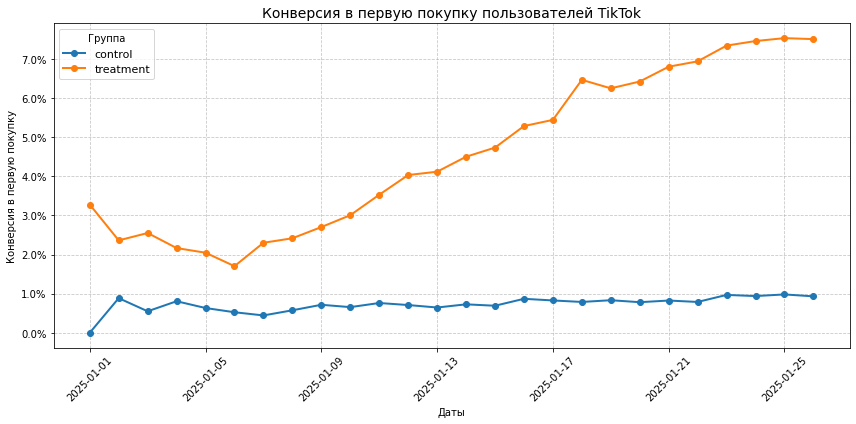

In [153]:
records = []

cohort['first_purchase_date'] = cohort['first_purchase_ts'].dt.date
dates = sorted(cohort['cohort_date'].unique())

for d in dates:
    df_window = cohort[
        cohort['cohort_date'] <= d
    ].copy()
    df_window['converted_cum'] = (
        (df_window['converted'] == 1) &
        (df_window['first_purchase_date'] <= d)
    ).astype(int)
    grouped = (
        df_window
        .groupby('group')['converted_cum']
        .agg(['sum', 'count'])
        .reset_index()
    )
    grouped.columns = ['group', 'conversions_cum', 'total_cum']
    grouped['cum_conversion'] = (grouped['conversions_cum'] / grouped['total_cum'].replace(0, pd.NA))
    grouped['date'] = d
    records.append(grouped)

df_cum = pd.concat(records, ignore_index = True)
df_cum['date'] = pd.to_datetime(df_cum['date'])
df_cum = df_cum.sort_values(['group', 'date'])

plt.figure(figsize = (12, 6))

for group in ['control', 'treatment']:
    if group in df_cum['group'].unique():
        df_plot = df_cum[df_cum['group'] == group]
        plt.plot(
            df_plot['date'],
            df_plot['cum_conversion'],
            marker = 'o',
            label = group,
            linewidth = 2
        )

plt.title('Конверсия в первую покупку пользователей TikTok', fontsize = 14)
plt.xlabel('Даты')
plt.ylabel('Конверсия в первую покупку')

plt.grid(True, linestyle = '--', alpha = 0.7)
plt.legend(title = 'Группа', fontsize = 11)
plt.xticks(rotation = 45)
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()

Разница большая, p‑value показывает, что тест статистически значим. Сильный разрыв увеличивается со временем, разница между группами не снижается. Такая положительная разница может говорить об успехе предоставления бонуса на первую покупку новым пользователям, привлеченным через TikTok. Нулевую гипотезу отвергаем.

Теперь вспомогательная метрика ARPU. Комиссия платформы - 5%. Будем использовать односторонний t-test.

H0 - ARPU в тестовой группе не выше, чем в контрольной группе.

H1 - ARPU в тестовой группе выше, чем в контрольной группе.

In [154]:
orders_21d['revenue'] = orders_21d['total_price'] * 0.05

user_revenue = (
    orders_21d
    .groupby('user_id')['revenue']
    .sum()
    .reset_index()
)

user_revenue.rename(columns = {'revenue': 'revenue_21d'}, inplace = True)

arpu_cohort = cohort[
    ['user_id', 'group']
].merge(
    user_revenue,
    on = 'user_id',
    how = 'left'
)

arpu_cohort['revenue_21d'] = (arpu_cohort['revenue_21d'].fillna(0))

arpu_agg = (
    arpu_cohort
    .groupby('group')['revenue_21d']
    .agg(['mean', 'count'])
    .rename(
        columns = {
            'mean': 'ARPU',
            'count': 'users'
        }
    )
)

arpu_control = arpu_cohort[arpu_cohort['group'] == 'control']['revenue_21d']
arpu_treatment = arpu_cohort[arpu_cohort['group'] == 'treatment']['revenue_21d']

t_stat, p_val = ttest_ind(
    arpu_treatment,
    arpu_control,
    equal_var = False,
    alternative = 'greater'
)

arpu_control_mean = arpu_agg.loc['control', 'ARPU']
arpu_treatment_mean = arpu_agg.loc['treatment', 'ARPU']
absolute_lift_arpu = (arpu_treatment_mean - arpu_control_mean)
relative_lift_arpu = (100 * (arpu_treatment_mean / arpu_control_mean - 1) if arpu_control_mean != 0 else 0)

results_arpu = pd.DataFrame([{
    'Metric': 'ARPU',
    'Group A': 'control',
    'Group B': 'treatment',
    'p-value': p_val,
    'ARPU A': arpu_control_mean,
    'ARPU B': arpu_treatment_mean,
    'Absolute Lift': absolute_lift_arpu,
    'Relative Lift (%)': relative_lift_arpu
}])

results_arpu

,Metric,Group A,Group B,p-value,ARPU A,ARPU B,Absolute Lift,Relative Lift (%)
0,ARPU,control,treatment,1.527537e-09,11.663483,131.249045,119.585563,1025.298924


p‑value показывает, что разница между группами теста статистически значима.

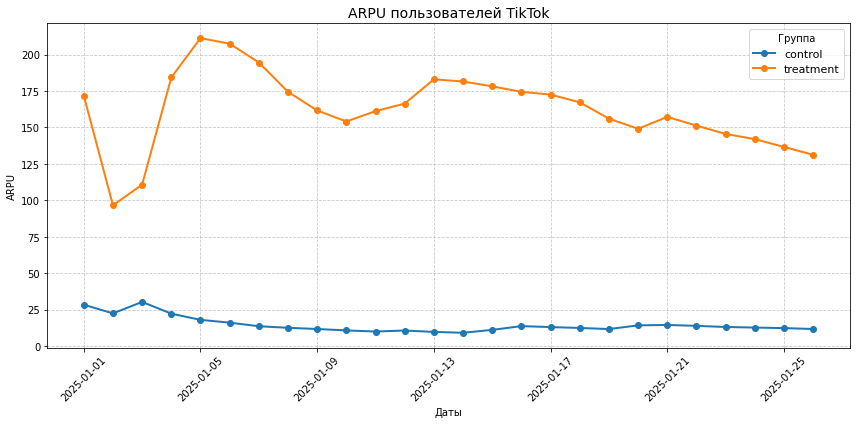

In [155]:
records = []

for d in dates:
    df_window = arpu_cohort[cohort['cohort_date'] <= d].copy()
    grouped = (
        df_window
        .groupby('group')['revenue_21d']
        .agg(['mean', 'count'])
        .reset_index()
    )
    grouped.columns = ['group', 'arpu', 'total_users']
    grouped['date'] = d
    records.append(grouped)

df_arpu_cum = pd.concat(records, ignore_index = True)
df_arpu_cum['date'] = pd.to_datetime(df_arpu_cum['date'])
df_arpu_cum = df_arpu_cum.sort_values(['group', 'date'])

plt.figure(figsize = (12, 6))

for group in ['control', 'treatment']:
    if group in df_arpu_cum['group'].unique():
        df_plot = df_arpu_cum[df_arpu_cum['group'] == group]
        plt.plot(
            df_plot['date'],
            df_plot['arpu'],
            marker = 'o',
            label = group,
            linewidth = 2
        )

plt.title('ARPU пользователей TikTok', fontsize = 14)
plt.xlabel('Даты')
plt.ylabel('ARPU')

plt.grid(True, linestyle = '--', alpha = 0.7)
plt.legend(title = 'Группа', fontsize = 11)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Разница в ARPU есть, p‑value показывает, что тест статистически значим. Разрыв со временем немного уменьшается, линия устаканивается. Бонус на первую покупку увеличивает ARPU пользователей, привлеченных через TikTok. Нулевую гипотезу отвергаем.

Теперь вспомогательная метрика ARPPU.

H0 - ARPPU в тестовой группе не выше, чем в контрольной группе.

H1 - ARPPU в тестовой группе выше, чем в контрольной группе.

In [156]:
user_revenue_arppu = (
    orders_21d
    .groupby('user_id')['revenue']
    .sum()
    .reset_index()
)

user_revenue_arppu.rename(columns = {'revenue': 'revenue_21d'},inplace = True)

user_revenue_arppu = user_revenue_arppu.merge(
    df_split_ab[['user_id', 'group']],
    on = 'user_id',
    how = 'left',
    validate = 'many_to_one'
)

arppu_agg = (
    user_revenue_arppu
    .groupby('group')['revenue_21d']
    .agg(['mean', 'count'])
    .rename(
        columns = {
            'mean': 'ARPPU',
            'count': 'buyers'
        }
    )
)

arppu_control = user_revenue_arppu[user_revenue_arppu['group'] == 'control']['revenue_21d']

arppu_treatment = user_revenue_arppu[user_revenue_arppu['group'] == 'treatment']['revenue_21d']

t_stat, p_val = ttest_ind(
    arppu_treatment,
    arppu_control,
    equal_var = False,
    alternative = 'greater'
)

arppu_control_mean = arppu_agg.loc['control', 'ARPPU']
arppu_treatment_mean = arppu_agg.loc['treatment', 'ARPPU']
absolute_lift_arppu = (arppu_treatment_mean - arppu_control_mean)
relative_lift_arppu = (100 * (arppu_treatment_mean / arppu_control_mean - 1) if arppu_control_mean != 0 else 0)

results_arppu = pd.DataFrame([{
    'Metric': 'ARPPU',
    'Group A': 'control',
    'Group B': 'treatment',
    'p-value': p_val,
    'ARPPU A': arppu_control_mean,
    'ARPPU B': arppu_treatment_mean,
    'Absolute Lift': absolute_lift_arppu,
    'Relative Lift (%)': relative_lift_arppu
}])

results_arppu

,Metric,Group A,Group B,p-value,ARPPU A,ARPPU B,Absolute Lift,Relative Lift (%)
0,ARPPU,control,treatment,0.050552,1252.158179,1747.99865,495.840471,39.598869


p‑value показывает, что разница между группами теста статистически не значима, но на самой грани.

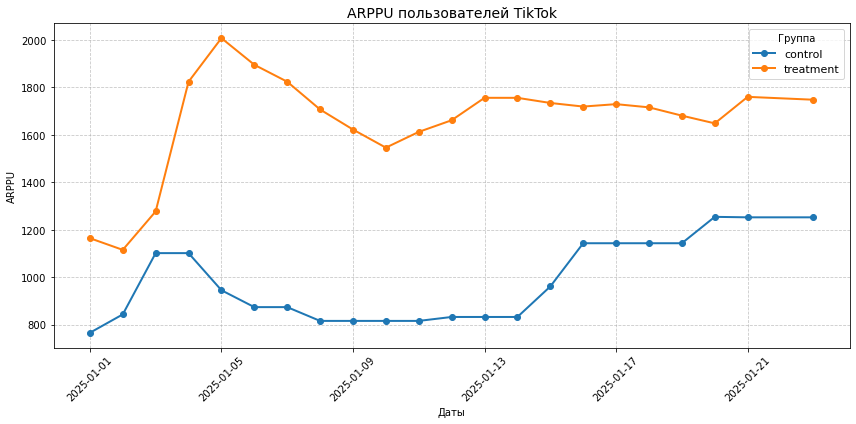

In [157]:
records = []

arppu_data = user_revenue_arppu.copy()

arppu_data = arppu_data.merge(
    df_abt[['user_id', 'registration_date']],
    on = 'user_id',
    how = 'left',
    validate = 'one_to_one'
)

arppu_data['cohort_date'] = (arppu_data['registration_date'].dt.date)
dates = sorted(arppu_data['cohort_date'].unique())

for d in dates:
    df_window = arppu_data[arppu_data['cohort_date'] <= d].copy()
    grouped = (
        df_window
        .groupby('group')['revenue_21d']
        .agg(['mean', 'count'])
        .reset_index()
    )
    grouped.columns = ['group', 'arppu', 'buyers']
    grouped['date'] = d
    records.append(grouped)

df_arppu_cum = pd.concat(records, ignore_index = True)
df_arppu_cum['date'] = pd.to_datetime(df_arppu_cum['date'])
df_arppu_cum = df_arppu_cum.sort_values(['group', 'date'])

plt.figure(figsize = (12, 6))

for group in ['control', 'treatment']:
    if group in df_arppu_cum['group'].unique():
        df_plot = df_arppu_cum[df_arppu_cum['group'] == group]
        plt.plot(
            df_plot['date'],
            df_plot['arppu'],
            marker = 'o',
            label = group,
            linewidth = 2
        )

plt.title('ARPPU пользователей TikTok', fontsize = 14)
plt.xlabel('Даты')
plt.ylabel('ARPPU')

plt.grid(True, linestyle = '--', alpha = 0.7)
plt.legend(title = 'Группа', fontsize = 11)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Нулевую гипотезу нельзя отвергнуть, хоть и ARPPU в тестовой группе выше. К концу графика значения выравниваются.

Рассчитаем вспомогательную метрику AOV.

H0 - AOV в тестовой группе не выше, чем в контрольной группе.

H1 - AOV в тестовой группе выше, чем в контрольной группе.

In [158]:
user_aov = (
    orders_21d
    .groupby(['user_id', 'group'])['total_price']
    .mean()
    .reset_index()
    .rename(columns = {'total_price': 'aov_21d'})
)

aov_agg = (
    user_aov
    .groupby('group')['aov_21d']
    .agg(['mean', 'count'])
    .rename(
        columns = {
            'mean': 'AOV',
            'count': 'users'
        }
    )
)

aov_control = user_aov[user_aov['group'] == 'control']['aov_21d']
aov_treatment = user_aov[user_aov['group'] == 'treatment']['aov_21d']

t_stat, p_val = ttest_ind(
    aov_treatment,
    aov_control,
    equal_var = False,
    alternative = 'greater'
)

aov_control_mean = aov_agg.loc['control', 'AOV']
aov_treatment_mean = aov_agg.loc['treatment', 'AOV']
absolute_lift_aov = (aov_treatment_mean - aov_control_mean)
relative_lift_aov = (100 * (aov_treatment_mean / aov_control_mean - 1) if aov_control_mean != 0 else 0)

results_aov = pd.DataFrame([{
    'Metric': 'AOV',
    'Group A': 'control',
    'Group B': 'treatment',
    'p-value': p_val,
    'AOV A': aov_control_mean,
    'AOV B': aov_treatment_mean,
    'Absolute Lift': absolute_lift_aov,
    'Relative Lift (%)': relative_lift_aov
}])

results_aov

,Metric,Group A,Group B,p-value,AOV A,AOV B,Absolute Lift,Relative Lift (%)
0,AOV,control,treatment,0.75931,19945.747786,16539.644577,-3406.103208,-17.076839


p‑value показывает, что разница между группами теста статистически не значима.

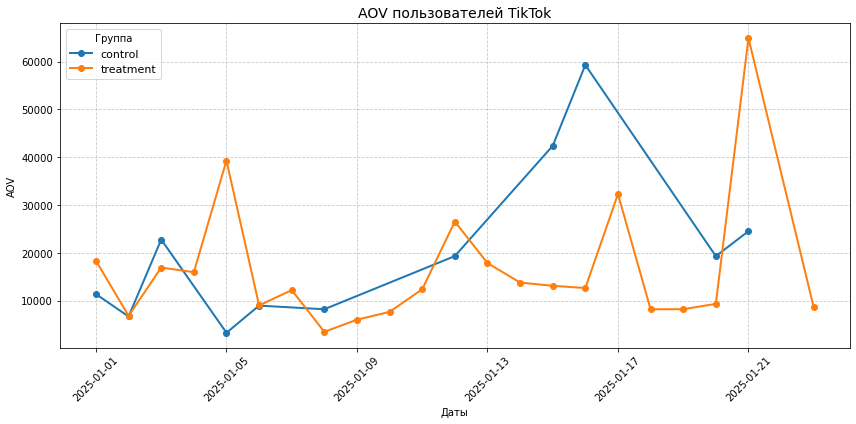

In [159]:
records = []

aov_data = user_aov.merge(
    df_abt[['user_id', 'registration_date']],
    on = 'user_id',
    how = 'left',
    validate = 'one_to_one'
)

aov_data['cohort_date'] = (aov_data['registration_date'].dt.date)
dates = sorted(aov_data['cohort_date'].unique())

for d in dates:
    df_window = aov_data[aov_data['cohort_date'] == d].copy()
    grouped = (
        df_window
        .groupby('group')['aov_21d']
        .agg(['mean', 'count'])
        .reset_index()
    )
    grouped.columns = ['group', 'aov', 'users']
    grouped['date'] = d
    records.append(grouped)

df_aov_cum = pd.concat(records, ignore_index = True)
df_aov_cum['date'] = pd.to_datetime(df_aov_cum['date'])
df_aov_cum = df_aov_cum.sort_values(['group', 'date'])

plt.figure(figsize = (12, 6))

for group in ['control', 'treatment']:
    if group in df_aov_cum['group'].unique():
        df_plot = df_aov_cum[df_aov_cum['group'] == group]
        plt.plot(
            df_plot['date'],
            df_plot['aov'],
            marker = 'o',
            label = group,
            linewidth = 2
        )

plt.title('AOV пользователей TikTok', fontsize = 14)
plt.xlabel('Даты')
plt.ylabel('AOV')

plt.grid(True, linestyle = '--', alpha = 0.7)
plt.legend(title = 'Группа', fontsize = 11)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Нулевую гипотезу нельзя отвергнуть, снижение среднего чека из-за бонуса статистически не значимо.

Теперь изучим барьерную мертику.

H0 - Средняя выручка на пользователя тестовой группе не выросла.

H1 - Средняя выручка на пользователя тестовой группе выросла.

In [160]:
revenue_agg = (
    orders_21d
    .groupby('group')['revenue']
    .agg(['sum', 'count'])
    .rename(
        columns = {
            'sum': 'total_revenue',
            'count': 'orders'
        }
    )
)

user_revenue = (
    orders_21d
    .groupby('user_id')['revenue']
    .sum()
    .reset_index()
    .rename(columns = {'revenue': 'revenue_21d'})
)

user_revenue = user_revenue.merge(
    df_split_ab[['user_id', 'group']],
    on = 'user_id',
    how = 'right',
    validate = 'one_to_one'
)

user_revenue['revenue_21d'] = (user_revenue['revenue_21d'].fillna(0))

revenue_user_agg = (
    user_revenue
    .groupby('group')['revenue_21d']
    .agg(['mean', 'count'])
    .rename(
        columns = {
            'mean': 'revenue_per_user',
            'count': 'users'
        }
    )
)

revenue_control = user_revenue[user_revenue['group'] == 'control']['revenue_21d']
revenue_treatment = user_revenue[user_revenue['group'] == 'treatment']['revenue_21d']

t_stat, p_val = ttest_ind(
    revenue_treatment,
    revenue_control,
    equal_var = False,
    alternative = 'greater'
)

revenue_per_user_control = revenue_user_agg.loc['control', 'revenue_per_user']
revenue_per_user_treatment = revenue_user_agg.loc['treatment', 'revenue_per_user']
absolute_lift_revenue = (revenue_per_user_treatment - revenue_per_user_control)
relative_lift_revenue = (100 * (revenue_per_user_treatment / revenue_per_user_control - 1) if revenue_per_user_control != 0 else 0)

results_revenue = pd.DataFrame([{
    'Metric': 'Revenue per User',
    'Group A': 'control',
    'Group B': 'treatment',
    'p-value': p_val,
    'Revenue per User A': revenue_per_user_control,
    'Revenue per User B': revenue_per_user_treatment,
    'Absolute Lift': absolute_lift_revenue,
    'Relative Lift (%)': relative_lift_revenue
}])

results_revenue

,Metric,Group A,Group B,p-value,Revenue per User A,Revenue per User B,Absolute Lift,Relative Lift (%)
0,Revenue per User,control,treatment,1.527537e-09,11.663483,131.249045,119.585563,1025.298924


p‑value показывает, что разница между группами теста статистически значима.

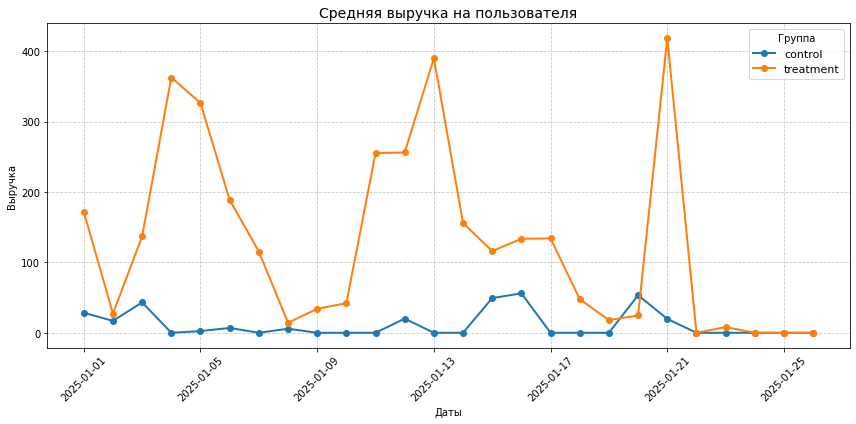

In [161]:
records = []

revenue_data = user_revenue.merge(
    df_abt[['user_id', 'registration_date']],
    on = 'user_id',
    how = 'left',
    validate = 'one_to_one'
)

revenue_data['cohort_date'] = (revenue_data['registration_date'].dt.date)
dates = sorted(revenue_data['cohort_date'].unique())

for d in dates:
    df_day = revenue_data[revenue_data['cohort_date'] == d].copy()
    grouped = (
        df_day
        .groupby('group')['revenue_21d']
        .agg(['mean', 'count'])
        .reset_index()
    )
    grouped.columns = ['group', 'revenue_per_user', 'users']
    grouped['date'] = d
    records.append(grouped)

df_revenue_daily = pd.concat(records, ignore_index = True)
df_revenue_daily['date'] = pd.to_datetime(df_revenue_daily['date'])
df_revenue_daily = df_revenue_daily.sort_values(['group', 'date'])

plt.figure(figsize = (12, 6))

for group in ['control', 'treatment']:
    df_plot = df_revenue_daily[df_revenue_daily['group'] == group]
    plt.plot(
        df_plot['date'],
        df_plot['revenue_per_user'],
        marker = 'o',
        label = group,
        linewidth = 2
    )

plt.title('Средняя выручка на пользователя', fontsize = 14)
plt.xlabel('Даты')
plt.ylabel('Выручка')

plt.grid(True, linestyle = '--', alpha = 0.7)
plt.legend(title = 'Группа', fontsize = 11)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Барьерная метрика не ухудшидась, можно отвергнуть нулевую гипотезу.

### Анализ изменения трат

Используя бутстрап, сравним разницы перцентилей (25, 50, 75) суммы всех покупок платящих пользователей в контрольной и тестовой группах.

In [162]:
user_orders_sum = (
    orders_21d
    .groupby('user_id')['total_price']
    .sum()
    .reset_index()
    .rename(columns = {'total_price': 'orders_sum_21d'})
)

user_orders_sum = user_orders_sum.merge(
    df_split_ab[['user_id', 'group']],
    on = 'user_id',
    how = 'right',
    validate = 'one_to_one'
)

user_orders_sum['orders_sum_21d'] = (user_orders_sum['orders_sum_21d'].fillna(0))
control = user_orders_sum[(user_orders_sum['group'] == 'control') & (user_orders_sum['orders_sum_21d'] > 0)]['orders_sum_21d'].values
treatment = user_orders_sum[(user_orders_sum['group'] == 'treatment') & (user_orders_sum['orders_sum_21d'] > 0)]['orders_sum_21d'].values

In [163]:
np.random.seed(41)

n_iterations = 1000
boot_diffs = []

for i in range(n_iterations):
    boot_control = np.random.choice(
        control,
        size = len(control),
        replace = True
    )
    boot_treatment = np.random.choice(
        treatment,
        size = len(treatment),
        replace = True
    )
    control_25p = np.percentile(boot_control, 25)
    treatment_25p = np.percentile(boot_treatment, 25)
    boot_diffs.append(treatment_25p - control_25p)

boot_diffs = np.array(boot_diffs)
diff_ci = np.percentile(boot_diffs, [2.5, 97.5])

print(f"25-й перцентиль контрольной группы: "f"{np.percentile(control, 25):.2f}")
print(f"25-й перцентиль тестовой группы: "f"{np.percentile(treatment, 25):.2f}")
print(f"95%-й доверительный интервал разности 25-х перцентилей "f"[{diff_ci[0]:.2f}, {diff_ci[1]:.2f}]")

25-й перцентиль контрольной группы: 15012.00
25-й перцентиль тестовой группы: 5511.90
95%-й доверительный интервал разности 25-х перцентилей [-16893.91, -827.13]


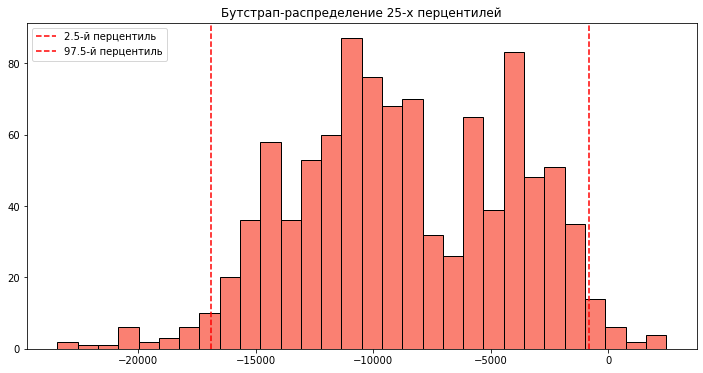

In [164]:
plt.figure(figsize = (12, 6))

plt.hist(boot_diffs, bins = 30, color = 'salmon', edgecolor = 'black')
plt.axvline(diff_ci[0], color = 'red', linestyle = '--', label = '2.5-й перцентиль')
plt.axvline(diff_ci[1], color = 'red', linestyle = '--', label = '97.5-й перцентиль')
plt.title("Бутстрап-распределение 25-х перцентилей")
plt.legend()
plt.show()

Весь доверительный интервал находится ниже 0, значит различие статистически значимо. Получается бонус конвертирурет в покупку больше пользователей, среди них больше людей с небольшими суммами заказов.

In [165]:
boot_diffs = []

for i in range(n_iterations):
    boot_control = np.random.choice(
        control,
        size = len(control),
        replace = True
    )
    boot_treatment = np.random.choice(
        treatment,
        size = len(treatment),
        replace = True
    )
    control_50p = np.percentile(boot_control, 50)
    treatment_50p = np.percentile(boot_treatment, 50)
    boot_diffs.append(treatment_50p - control_50p)

boot_diffs = np.array(boot_diffs)
diff_ci = np.percentile(boot_diffs, [2.5, 97.5])

print(f"50-й перцентиль контрольной группы: "f"{np.percentile(control, 50):.2f}")
print(f"50-й перцентиль тестовой группы: "f"{np.percentile(treatment, 50):.2f}")
print(f"95%-й доверительный интервал разности 50-х перцентилей "f"[{diff_ci[0]:.2f}, {diff_ci[1]:.2f}]")

50-й перцентиль контрольной группы: 22235.97
50-й перцентиль тестовой группы: 16551.18
95%-й доверительный интервал разности 50-х перцентилей [-17990.15, 7373.10]


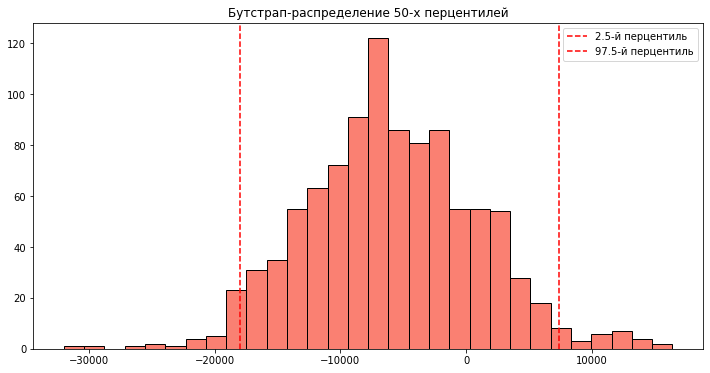

In [166]:
plt.figure(figsize = (12, 6))

plt.hist(boot_diffs, bins = 30, color = 'salmon', edgecolor = 'black')
plt.axvline(diff_ci[0], color = 'red', linestyle = '--', label = '2.5-й перцентиль')
plt.axvline(diff_ci[1], color = 'red', linestyle = '--', label = '97.5-й перцентиль')
plt.title("Бутстрап-распределение 50-х перцентилей")
plt.legend()
plt.show()

Интервал содержит 0, так что значимых изменений нет. Скорее пурукос влево из-за небольших сумм.

In [167]:
boot_diffs = []

for i in range(n_iterations):
    boot_control = np.random.choice(
        control,
        size = len(control),
        replace = True
    )
    boot_treatment = np.random.choice(
        treatment,
        size = len(treatment),
        replace = True
    )
    control_75p = np.percentile(boot_control, 75)
    treatment_75p = np.percentile(boot_treatment, 75)
    boot_diffs.append(treatment_75p - control_75p)

boot_diffs = np.array(boot_diffs)
diff_ci = np.percentile(boot_diffs, [2.5, 97.5])

print(f"75-й перцентиль контрольной группы: "f"{np.percentile(control, 75):.2f}")
print(f"75-й перцентиль тестовой группы: "f"{np.percentile(treatment, 75):.2f}")
print(f"95%-й доверительный интервал разности 75-х перцентилей "f"[{diff_ci[0]:.2f}, {diff_ci[1]:.2f}]")

75-й перцентиль контрольной группы: 31019.81
75-й перцентиль тестовой группы: 43863.50
95%-й доверительный интервал разности 75-х перцентилей [-8383.74, 29204.02]


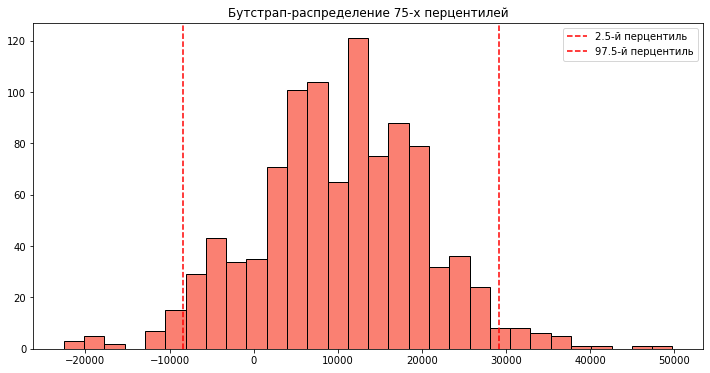

In [168]:
plt.figure(figsize = (12, 6))

plt.hist(boot_diffs, bins = 30, color = 'salmon', edgecolor = 'black')
plt.axvline(diff_ci[0], color = 'red', linestyle = '--', label = '2.5-й перцентиль')
plt.axvline(diff_ci[1], color = 'red', linestyle = '--', label = '97.5-й перцентиль')
plt.title("Бутстрап-распределение 75-х перцентилей")
plt.legend()
plt.show()

Тоже статистически не значимое изменение. Бонус, вероятно, увеличивает конверсию за счёт пользователей с меньшим объёмом покупок.

Воронка тестовой группы лучше, больше пользователей переходят к чекауту и совершают покупку. Основная метрика кратно выросла - предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приводит к увеличению конверсии в первую покупку, этот эффект статистически значим. Вспомогательные метрики показали, что бонус побуждает к самой первой покупке, но статистически значимо не увеличивает средний доход с покупателя, не увеличивает средний чек. Но бонус и не ухудшает монетизацию, вредных эффектов нет. Барьерная метрика не ухудшидась.

## Итоги исследования

В целом эксперимент можно считать успешным.

Гипотеза о предоставлении бонуса на первую покупку новым пользователям, привлеченным через TikTok, судя по данным, приводит к увеличению конверсии в первую покупку. Среди них появляется больше покупателей с небольшими суммами заказов. Статистически значимого ухудшения монетизации нет.

Рекомендуется проверить, сколько внедрение бонуса будет стоить, на сколько вырастет маркетинговый бюджет (на ТикТок и так выделяется очень много денег), окупится ли. Если всё в порядке, масштабиорвать бонус на весь канал.